In [1]:
# ============================================================
# 0. INSTALL / IMPORTS
# ============================================================
!pip -q install -U scikit-learn seaborn opencv-python-headless

import os
import glob
import zipfile
import time
import random
import shutil
import subprocess
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

AUTOTUNE = tf.data.AUTOTUNE

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 67.2 MB/s eta 0:00:00:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.2/61.2 MB 29.3 MB/s eta 0:00:00:00:0100:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sklearn-compat 0.1.5 requires scikit-learn<1.9,>=1.2, but you have scikit-learn 1.9.1 which is incompatible.
TensorFlow: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [4]:
# ============================================================
# 1. DOWNLOAD AND EXTRACT OFFICIAL UCI HAR DATASET
# ============================================================

from pathlib import Path
import urllib.request
import zipfile
import os

DATA_ROOT = Path("/kaggle/working")
ZIP_PATH = DATA_ROOT / "uci_har.zip"
EXTRACT_DIR = DATA_ROOT / "uci_har"

UCI_URL = (
    "https://archive.ics.uci.edu/static/public/240/"
    "human+activity+recognition+using+smartphones.zip"
)

# ------------------------------------------------------------
# Step 1: Download the official UCI dataset
# ------------------------------------------------------------

if not ZIP_PATH.exists():

    print("Downloading official UCI HAR dataset...")

    urllib.request.urlretrieve(
        UCI_URL,
        ZIP_PATH
    )

    print(
        "Download complete:",
        round(ZIP_PATH.stat().st_size / (1024**2), 2),
        "MB"
    )

else:
    print("ZIP file already exists:")
    print(ZIP_PATH)


# ------------------------------------------------------------
# Step 2: Extract the downloaded ZIP
# ------------------------------------------------------------

EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

print("\nExtracting dataset...")

with zipfile.ZipFile(ZIP_PATH, "r") as z:

    z.extractall(EXTRACT_DIR)

print("Extraction complete.")


# ------------------------------------------------------------
# Step 3: Find the actual UCI HAR Dataset directory
# ------------------------------------------------------------

dataset_candidates = list(
    EXTRACT_DIR.rglob("UCI HAR Dataset")
)

if dataset_candidates:

    DATA_DIR = dataset_candidates[0]

else:

    # Sometimes the extracted dataset may be nested differently.
    # Search for the y_train.txt file instead.
    
    y_train_candidates = list(
        EXTRACT_DIR.rglob("y_train.txt")
    )

    if not y_train_candidates:

        raise FileNotFoundError(
            "Could not find the UCI HAR dataset after extraction."
        )

    # y_train.txt is inside:
    # UCI HAR Dataset/train/y_train.txt
    DATA_DIR = y_train_candidates[0].parent.parent


# ------------------------------------------------------------
# Step 4: Verify the dataset structure
# ------------------------------------------------------------

print("\nDataset directory:")
print(DATA_DIR)

print("\nDataset exists:", DATA_DIR.exists())

TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "test"

TRAIN_SIGNAL_DIR = TRAIN_DIR / "Inertial Signals"
TEST_SIGNAL_DIR = TEST_DIR / "Inertial Signals"

print("\nChecking dataset structure:")

print("Train directory:",
      TRAIN_DIR.exists())

print("Test directory:",
      TEST_DIR.exists())

print("Train Inertial Signals:",
      TRAIN_SIGNAL_DIR.exists())

print("Test Inertial Signals:",
      TEST_SIGNAL_DIR.exists())


# ------------------------------------------------------------
# Step 5: Check one required raw signal file
# ------------------------------------------------------------

required_file = (
    TRAIN_SIGNAL_DIR / "body_acc_x_train.txt"
)

print("\nChecking required raw signal file:")
print(required_file)

print("Exists:", required_file.exists())


if not required_file.exists():

    raise FileNotFoundError(
        "\nRequired raw signal file was not found."
        "\nPlease check the extracted dataset structure."
    )

print("\n✓ UCI HAR dataset loaded successfully.")
print("✓ Raw inertial signal files are available.")

Download complete: 58.18 MB

Extracting dataset...
Extraction complete.


FileNotFoundError: Could not find the UCI HAR dataset after extraction.

In [5]:
# ============================================================
# 1. EXTRACT UCI HAR DATASET CORRECTLY
# ============================================================

from pathlib import Path
import zipfile
import os

DATA_ROOT = Path("/kaggle/working")
ZIP_PATH = DATA_ROOT / "uci_har.zip"
EXTRACT_DIR = DATA_ROOT / "uci_har"

# ------------------------------------------------------------
# Step 1: Extract the outer ZIP
# ------------------------------------------------------------

print("Extracting outer ZIP...")

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(EXTRACT_DIR)

print("Outer ZIP extracted.")


# ------------------------------------------------------------
# Step 2: Find the nested UCI HAR Dataset ZIP
# ------------------------------------------------------------

nested_zips = list(
    EXTRACT_DIR.rglob("UCI HAR Dataset.zip")
)

print("\nNested ZIP files found:")
for z in nested_zips:
    print(z)


if not nested_zips:
    raise FileNotFoundError(
        "UCI HAR Dataset.zip was not found."
    )

NESTED_ZIP = nested_zips[0]


# ------------------------------------------------------------
# Step 3: Extract the nested ZIP
# ------------------------------------------------------------

NESTED_EXTRACT_DIR = EXTRACT_DIR / "dataset_extracted"

NESTED_EXTRACT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("\nExtracting nested UCI HAR ZIP...")

with zipfile.ZipFile(NESTED_ZIP, "r") as z:
    z.extractall(NESTED_EXTRACT_DIR)

print("Nested ZIP extracted.")


# ------------------------------------------------------------
# Step 4: Find y_train.txt
# ------------------------------------------------------------

y_train_candidates = list(
    NESTED_EXTRACT_DIR.rglob("y_train.txt")
)

print("\nSearching for y_train.txt...")

if not y_train_candidates:

    raise FileNotFoundError(
        "y_train.txt still could not be found after extracting the nested ZIP."
    )

print("Found:")
for f in y_train_candidates:
    print(f)


# ------------------------------------------------------------
# Step 5: Determine DATA_DIR
# ------------------------------------------------------------

# Expected structure:
#
# UCI HAR Dataset/
# ├── train/
# │   ├── y_train.txt
# │   └── Inertial Signals/
# └── test/
#
# Therefore:
# y_train.txt.parent = train
# train.parent = UCI HAR Dataset

DATA_DIR = y_train_candidates[0].parent.parent

print("\n==========================================")
print("DATASET LOCATION")
print("==========================================")

print(DATA_DIR)
print("Exists:", DATA_DIR.exists())


# ------------------------------------------------------------
# Step 6: Define train/test directories
# ------------------------------------------------------------

TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "test"

TRAIN_SIGNAL_DIR = TRAIN_DIR / "Inertial Signals"
TEST_SIGNAL_DIR = TEST_DIR / "Inertial Signals"


# ------------------------------------------------------------
# Step 7: Verify dataset structure
# ------------------------------------------------------------

print("\n==========================================")
print("DATASET STRUCTURE")
print("==========================================")

print("Train directory:",
      TRAIN_DIR.exists())

print("Test directory:",
      TEST_DIR.exists())

print("Train Inertial Signals:",
      TRAIN_SIGNAL_DIR.exists())

print("Test Inertial Signals:",
      TEST_SIGNAL_DIR.exists())


# ------------------------------------------------------------
# Step 8: Verify required raw signal files
# ------------------------------------------------------------

required_files = [
    TRAIN_SIGNAL_DIR / "body_acc_x_train.txt",
    TRAIN_SIGNAL_DIR / "body_acc_y_train.txt",
    TRAIN_SIGNAL_DIR / "body_acc_z_train.txt",
    TRAIN_SIGNAL_DIR / "body_gyro_x_train.txt",
    TRAIN_SIGNAL_DIR / "body_gyro_y_train.txt",
    TRAIN_SIGNAL_DIR / "body_gyro_z_train.txt",
    TRAIN_SIGNAL_DIR / "total_acc_x_train.txt",
    TRAIN_SIGNAL_DIR / "total_acc_y_train.txt",
    TRAIN_SIGNAL_DIR / "total_acc_z_train.txt",
]

print("\n==========================================")
print("CHECKING RAW SIGNAL FILES")
print("==========================================")

for file in required_files:
    print(
        file.name,
        "->",
        file.exists()
    )


# ------------------------------------------------------------
# Final check
# ------------------------------------------------------------

if all(file.exists() for file in required_files):

    print("\n✓ UCI HAR DATASET FOUND")
    print("✓ TRAIN/TEST DATA FOUND")
    print("✓ ALL 9 RAW INERTIAL SIGNAL CHANNELS FOUND")
    print("\nDATA_DIR =", DATA_DIR)

else:

    raise FileNotFoundError(
        "\nOne or more required raw inertial signal files are missing."
    )

Extracting outer ZIP...
Outer ZIP extracted.

Nested ZIP files found:
/kaggle/working/uci_har/UCI HAR Dataset.zip

Extracting nested UCI HAR ZIP...
Nested ZIP extracted.

Searching for y_train.txt...
Found:
/kaggle/working/uci_har/dataset_extracted/UCI HAR Dataset/train/y_train.txt

DATASET LOCATION
/kaggle/working/uci_har/dataset_extracted/UCI HAR Dataset
Exists: True

DATASET STRUCTURE
Train directory: True
Test directory: True
Train Inertial Signals: True
Test Inertial Signals: True

CHECKING RAW SIGNAL FILES
body_acc_x_train.txt -> True
body_acc_y_train.txt -> True
body_acc_z_train.txt -> True
body_gyro_x_train.txt -> True
body_gyro_y_train.txt -> True
body_gyro_z_train.txt -> True
total_acc_x_train.txt -> True
total_acc_y_train.txt -> True
total_acc_z_train.txt -> True

✓ UCI HAR DATASET FOUND
✓ TRAIN/TEST DATA FOUND
✓ ALL 9 RAW INERTIAL SIGNAL CHANNELS FOUND

DATA_DIR = /kaggle/working/uci_har/dataset_extracted/UCI HAR Dataset


In [6]:
# ============================================================
# 2. LOAD 128 x 9 INERTIAL SIGNAL WINDOWS
# ============================================================

ACTIVITY_NAMES = {
    1: "WALKING",
    2: "WALKING_UPSTAIRS",
    3: "WALKING_DOWNSTAIRS",
    4: "SITTING",
    5: "STANDING",
    6: "LAYING"
}

CHANNEL_FILES = [
    "body_acc_x_{split}.txt",
    "body_acc_y_{split}.txt",
    "body_acc_z_{split}.txt",

    "body_gyro_x_{split}.txt",
    "body_gyro_y_{split}.txt",
    "body_gyro_z_{split}.txt",

    "total_acc_x_{split}.txt",
    "total_acc_y_{split}.txt",
    "total_acc_z_{split}.txt",
]

CHANNEL_NAMES = [
    "body_acc_x",
    "body_acc_y",
    "body_acc_z",

    "body_gyro_x",
    "body_gyro_y",
    "body_gyro_z",

    "total_acc_x",
    "total_acc_y",
    "total_acc_z"
]


def load_inertial_split(split, root=DATA_DIR):

    signal_dir = root / split / "Inertial Signals"

    arrays = []

    for template in CHANNEL_FILES:

        path = signal_dir / template.format(
            split=split
        )

        arr = np.loadtxt(path)

        arrays.append(arr)

    # Each individual channel:
    # (N, 128)

    # Stack channels:
    # (N, 128, 9)

    X = np.stack(
        arrays,
        axis=-1
    )

    y = np.loadtxt(
        root / split / f"y_{split}.txt",
        dtype=np.int64
    )

    return (
        X.astype(np.float32),
        y.astype(np.int64)
    )


X_train_official, y_train_official = \
    load_inertial_split("train")

X_test_official, y_test_official = \
    load_inertial_split("test")


print(
    "Official train shape:",
    X_train_official.shape
)

print(
    "Official test shape :",
    X_test_official.shape
)

print(
    "Channels:",
    CHANNEL_NAMES
)


assert X_train_official.shape[1:] == (128, 9)

assert X_test_official.shape[1:] == (128, 9)

assert set(
    np.unique(y_train_official)
) == set(range(1, 7))

Official train shape: (7352, 128, 9)
Official test shape : (2947, 128, 9)
Channels: ['body_acc_x', 'body_acc_y', 'body_acc_z', 'body_gyro_x', 'body_gyro_y', 'body_gyro_z', 'total_acc_x', 'total_acc_y', 'total_acc_z']


In [7]:
# ============================================================
# 3. CREATE BALANCED 3000-WINDOW LAB SUBSET
# ============================================================

WINDOWS_PER_CLASS = 500

NUM_CLASSES = 6

selected_indices = []


for cls in range(
    1,
    NUM_CLASSES + 1
):

    cls_indices = np.where(
        y_train_official == cls
    )[0]

    if len(cls_indices) < WINDOWS_PER_CLASS:

        raise ValueError(
            f"Class {cls} has only "
            f"{len(cls_indices)} samples; "
            f"cannot select "
            f"{WINDOWS_PER_CLASS}."
        )

    selected_indices.extend(
        cls_indices[:WINDOWS_PER_CLASS]
    )


selected_indices = np.array(
    selected_indices
)


rng = np.random.default_rng(SEED)

rng.shuffle(
    selected_indices
)


X_lab = X_train_official[
    selected_indices
]

y_lab = (
    y_train_official[
        selected_indices
    ] - 1
)

In [8]:
# ============================================================
# 4. TRAIN / VALIDATION / TEST SPLIT
# ============================================================

X_train, X_temp, y_train, y_temp = train_test_split(

    X_lab,
    y_lab,

    test_size=0.30,

    stratify=y_lab,

    random_state=SEED
)


X_val, X_test, y_val, y_test = train_test_split(

    X_temp,
    y_temp,

    test_size=0.50,

    stratify=y_temp,

    random_state=SEED
)


print("Input tensor shape:")

print(
    "Training  :",
    X_train.shape
)

print(
    "Validation:",
    X_val.shape
)

print(
    "Testing   :",
    X_test.shape
)


print(
    "\nNumber of classes:",
    NUM_CLASSES
)

print(
    "Features per time step:",
    X_train.shape[-1]
)

print(
    "Sequence length:",
    X_train.shape[1]
)


print("\nClass distribution:")

dist = pd.DataFrame({

    "train":
        pd.Series(y_train)
        .value_counts()
        .sort_index(),

    "validation":
        pd.Series(y_val)
        .value_counts()
        .sort_index(),

    "test":
        pd.Series(y_test)
        .value_counts()
        .sort_index()

})


dist.index = [
    ACTIVITY_NAMES[i + 1]
    for i in dist.index
]


display(dist)

Input tensor shape:
Training  : (2100, 128, 9)
Validation: (450, 128, 9)
Testing   : (450, 128, 9)

Number of classes: 6
Features per time step: 9
Sequence length: 128

Class distribution:


,train,validation,test
WALKING,350,75,75
WALKING_UPSTAIRS,350,75,75
WALKING_DOWNSTAIRS,350,75,75
SITTING,350,75,75
STANDING,350,75,75
LAYING,350,75,75


In [9]:
# ============================================================
# 5. NORMALIZATION USING TRAINING STATISTICS ONLY
# ============================================================

scaler = StandardScaler()


# Fit ONLY on training data
scaler.fit(
    X_train.reshape(
        -1,
        X_train.shape[-1]
    )
)


def scale_sequences(X):

    original_shape = X.shape

    X2 = X.reshape(
        -1,
        original_shape[-1]
    )

    X2 = scaler.transform(X2)

    return X2.reshape(
        original_shape
    ).astype(
        np.float32
    )


X_train = scale_sequences(
    X_train
)

X_val = scale_sequences(
    X_val
)

X_test = scale_sequences(
    X_test
)


print("After normalization:")

print(
    "Train mean:",
    X_train.mean(axis=(0, 1))
)

print(
    "Train std :",
    X_train.std(axis=(0, 1))
)

After normalization:
Train mean: [ 6.1606570e-10  3.6017653e-09  4.7134179e-08 -2.7266630e-08
  2.8928612e-08  8.8980663e-09 -1.9819609e-07 -9.5211547e-08
 -6.2377907e-08]
Train std : [0.9998839  0.9998421  0.9998343  0.99985486 0.99986017 0.9998603
 0.9999772  0.9999598  0.9999729 ]


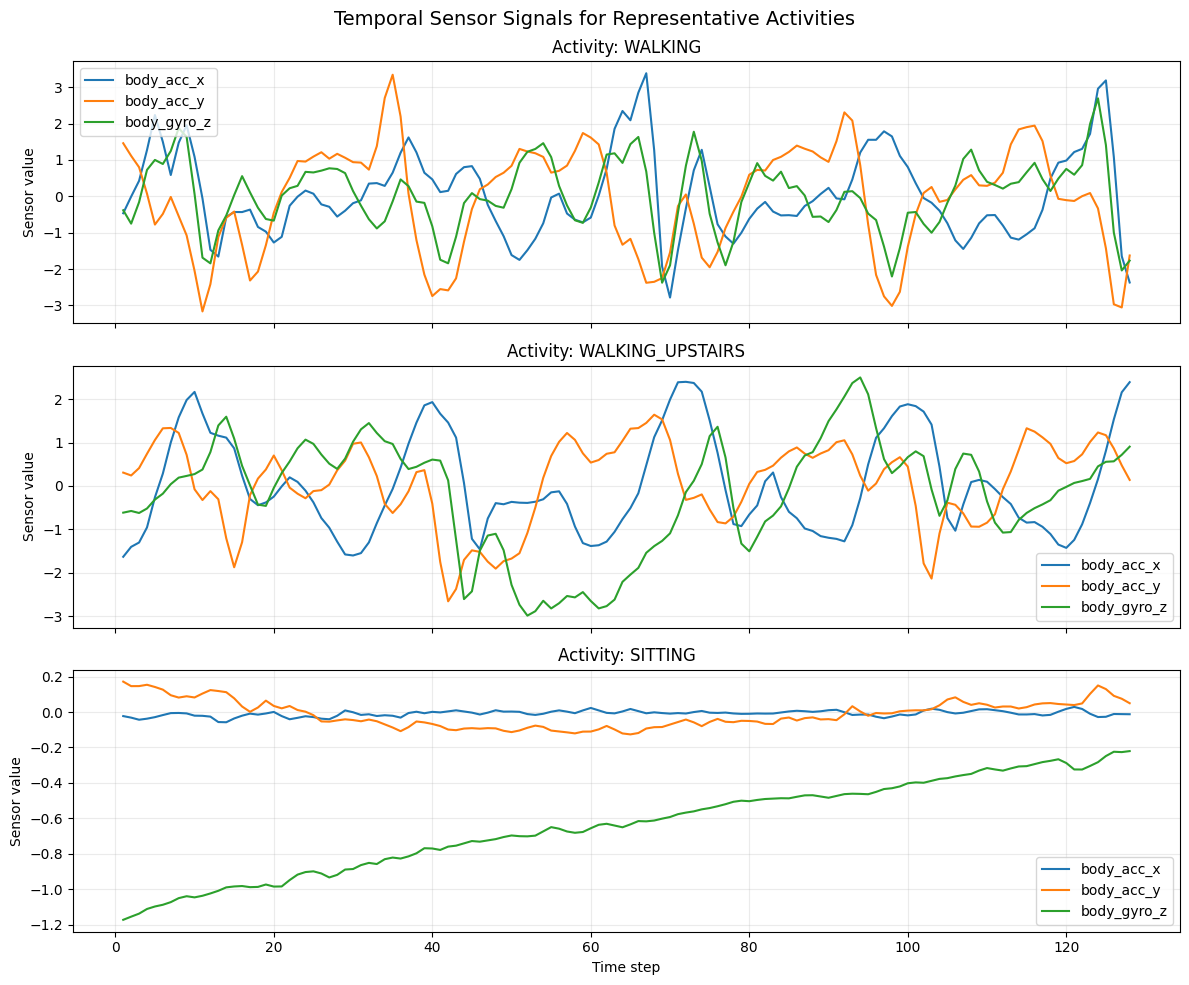

In [10]:
# ============================================================
# 6. TEMPORAL DATA VISUALIZATION — PLOT 1
# ============================================================

CHANNELS_TO_PLOT = [
    "body_acc_x",
    "body_acc_y",
    "body_gyro_z"
]

CHANNEL_INDICES = [
    CHANNEL_NAMES.index(ch)
    for ch in CHANNELS_TO_PLOT
]


classes_to_plot = [
    0,  # WALKING
    1,  # WALKING_UPSTAIRS
    3   # SITTING
]


fig, axes = plt.subplots(
    len(classes_to_plot),
    1,
    figsize=(12, 10),
    sharex=True
)


for row, cls in enumerate(
    classes_to_plot
):

    sample_idx = np.where(
        y_train == cls
    )[0][0]

    for channel_idx in CHANNEL_INDICES:

        axes[row].plot(
            np.arange(1, 129),
            X_train[
                sample_idx,
                :,
                channel_idx
            ],
            label=CHANNEL_NAMES[
                channel_idx
            ]
        )

    axes[row].set_ylabel(
        "Sensor value"
    )

    axes[row].set_title(
        f"Activity: {ACTIVITY_NAMES[cls + 1]}"
    )

    axes[row].grid(
        alpha=0.25
    )

    axes[row].legend()


axes[-1].set_xlabel(
    "Time step"
)

fig.suptitle(
    "Temporal Sensor Signals for Representative Activities",
    fontsize=14
)

plt.tight_layout()

plt.show()

In [11]:
# ============================================================
# 7. VANILLA RNN NUMERICAL EXERCISE
# ============================================================

x_values = [
    0.5,
    0.7,
    0.2
]

h = 0.0

Wx = 0.5
Wh = 0.8
b = 0.1


manual_hidden_states = []


for t, x in enumerate(
    x_values,
    start=1
):

    h = np.tanh(
        Wx * x
        + Wh * h
        + b
    )

    manual_hidden_states.append(h)

    print(
        f"h{t} = {h:.6f}"
    )

h1 = 0.336376
h2 = 0.616352
h3 = 0.599958


In [12]:
# ============================================================
# 8. MODEL BUILDING FUNCTIONS
# ============================================================

LEARNING_RATE = 1e-3
BATCH_SIZE = 32
EPOCHS = 30

RECURRENT_UNITS = 32
DROPOUT_RATE = 0.2


def compile_model(model):

    optimizer = keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    )

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


def build_rnn_model(
    sequence_length=128,
    units=32
):

    model = keras.Sequential(
        [

            layers.Input(
                shape=(
                    sequence_length,
                    9
                )
            ),

            layers.SimpleRNN(
                units
            ),

            layers.Dropout(
                DROPOUT_RATE
            ),

            layers.Dense(
                16,
                activation="relu"
            ),

            layers.Dense(
                NUM_CLASSES,
                activation="softmax"
            )

        ],

        name="SimpleRNN_Model"
    )

    return compile_model(model)


def build_lstm_model(
    sequence_length=128,
    units=32
):

    model = keras.Sequential(
        [

            layers.Input(
                shape=(
                    sequence_length,
                    9
                )
            ),

            layers.LSTM(
                units
            ),

            layers.Dropout(
                DROPOUT_RATE
            ),

            layers.Dense(
                16,
                activation="relu"
            ),

            layers.Dense(
                NUM_CLASSES,
                activation="softmax"
            )

        ],

        name="LSTM_Model"
    )

    return compile_model(model)


def build_gru_model(
    sequence_length=128,
    units=32
):

    model = keras.Sequential(
        [

            layers.Input(
                shape=(
                    sequence_length,
                    9
                )
            ),

            layers.GRU(
                units
            ),

            layers.Dropout(
                DROPOUT_RATE
            ),

            layers.Dense(
                16,
                activation="relu"
            ),

            layers.Dense(
                NUM_CLASSES,
                activation="softmax"
            )

        ],

        name="GRU_Model"
    )

    return compile_model(model)

In [13]:
# ============================================================
# 9. CREATE BASELINE MODELS
# ============================================================

rnn_model = build_rnn_model()

lstm_model = build_lstm_model()

gru_model = build_gru_model()


print("\n================ RNN ================\n")
rnn_model.summary()


print("\n================ LSTM ================\n")
lstm_model.summary()


print("\n================ GRU ================\n")
gru_model.summary()

I0000 00:00:1789881842.283319      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1789881842.286346      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5



================ RNN ================



Model: "SimpleRNN_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           102 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,974 (7.71 KB)

 Trainable params: 1,974 (7.71 KB)

... (9 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 6)              │           102 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,758 (18.59 KB)

 Trainable params: 4,758 (18.59 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# ============================================================
# 10. TRAIN BASELINE RNN, LSTM AND GRU
# ============================================================

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Train RNN
# ------------------------------------------------------------

print("\n================ TRAINING RNN ================\n")

start_time = time.time()

rnn_history = rnn_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1
)

rnn_training_time = time.time() - start_time

print(
    "\nRNN training time:",
    round(rnn_training_time, 2),
    "seconds"
)


# ------------------------------------------------------------
# Train LSTM
# ------------------------------------------------------------

print("\n================ TRAINING LSTM ================\n")

start_time = time.time()

lstm_history = lstm_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1
)

lstm_training_time = time.time() - start_time

print(
    "\nLSTM training time:",
    round(lstm_training_time, 2),
    "seconds"
)


# ------------------------------------------------------------
# Train GRU
# ------------------------------------------------------------

print("\n================ TRAINING GRU ================\n")

start_time = time.time()

gru_history = gru_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1
)

gru_training_time = time.time() - start_time

print(
    "\nGRU training time:",
    round(gru_training_time, 2),
    "seconds"
)


================ TRAINING RNN ================

Epoch 1/30
19/66 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.2043 - loss: 1.9567

I0000 00:00:1789881847.759473     147 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


66/66 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - accuracy: 0.3900 - loss: 1.5998 - val_accuracy: 0.5244 - val_loss: 1.2960
Epoch 2/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.5229 - loss: 1.2131 - val_accuracy: 0.5244 - val_loss: 1.1230
Epoch 3/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.5433 - loss: 1.0979 - val_accuracy: 0.5956 - val_loss: 0.9408
Epoch 4/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.5576 - loss: 1.0004 - val_accuracy: 0.6067 - val_loss: 0.8611
Epoch 5/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.6262 - loss: 0.8339 - val_accuracy: 0.6400 - val_loss: 0.7525
Epoch 6/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.6276 - loss: 0.7783 - val_accuracy: 0.6489 - val_loss: 0.7039
Epoch 7/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.6486 - loss: 0.7271 - val_accuracy: 0.6667 - val_loss: 0.6697
Epoch 8/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.6600 - loss: 0.6890 - val_accuracy: 0.6689 - val_loss: 0.

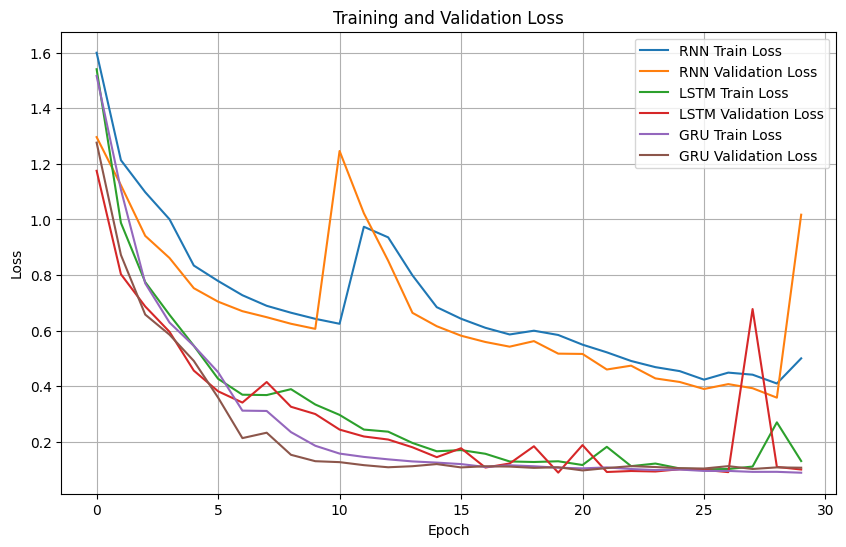

In [15]:
# ============================================================
# 11. PLOT TRAINING AND VALIDATION LOSS
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    rnn_history.history["loss"],
    label="RNN Train Loss"
)

plt.plot(
    rnn_history.history["val_loss"],
    label="RNN Validation Loss"
)

plt.plot(
    lstm_history.history["loss"],
    label="LSTM Train Loss"
)

plt.plot(
    lstm_history.history["val_loss"],
    label="LSTM Validation Loss"
)

plt.plot(
    gru_history.history["loss"],
    label="GRU Train Loss"
)

plt.plot(
    gru_history.history["val_loss"],
    label="GRU Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

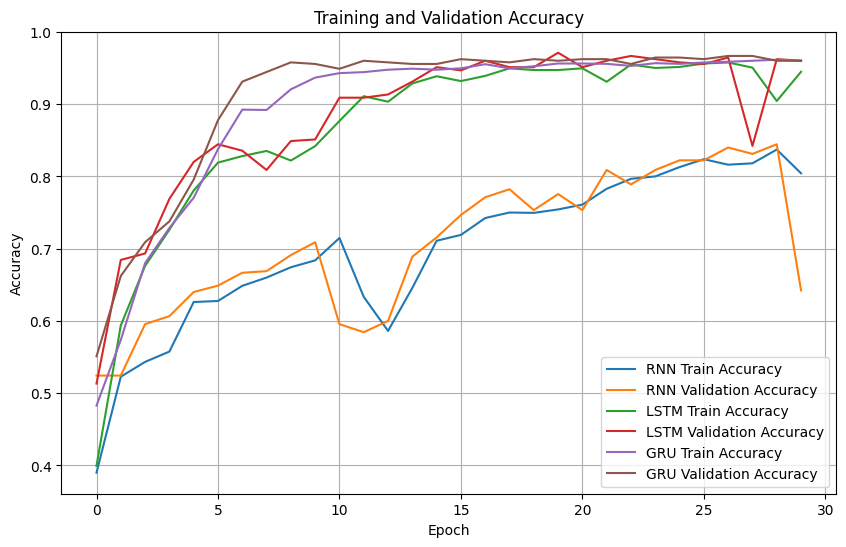

In [16]:
# ============================================================
# 12. PLOT TRAINING AND VALIDATION ACCURACY
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    rnn_history.history["accuracy"],
    label="RNN Train Accuracy"
)

plt.plot(
    rnn_history.history["val_accuracy"],
    label="RNN Validation Accuracy"
)

plt.plot(
    lstm_history.history["accuracy"],
    label="LSTM Train Accuracy"
)

plt.plot(
    lstm_history.history["val_accuracy"],
    label="LSTM Validation Accuracy"
)

plt.plot(
    gru_history.history["accuracy"],
    label="GRU Train Accuracy"
)

plt.plot(
    gru_history.history["val_accuracy"],
    label="GRU Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [17]:
# ============================================================
# 13. TEST METRICS
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# ------------------------------------------------------------
# Function to evaluate a model
# ------------------------------------------------------------

def evaluate_model(model, X_test, y_test):

    probabilities = model.predict(
        X_test,
        verbose=0
    )

    predictions = np.argmax(
        probabilities,
        axis=1
    )

    accuracy = accuracy_score(
        y_test,
        predictions
    )

    precision = precision_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0
    )

    cm = confusion_matrix(
        y_test,
        predictions
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "confusion_matrix": cm,
        "predictions": predictions
    }


# ------------------------------------------------------------
# Evaluate all models
# ------------------------------------------------------------

rnn_results = evaluate_model(
    rnn_model,
    X_test,
    y_test
)

lstm_results = evaluate_model(
    lstm_model,
    X_test,
    y_test
)

gru_results = evaluate_model(
    gru_model,
    X_test,
    y_test
)

In [18]:
# ============================================================
# 14. BASELINE MODEL COMPARISON
# ============================================================

comparison_df = pd.DataFrame({

    "Model": [
        "RNN",
        "LSTM",
        "GRU"
    ],

    "Test Accuracy": [
        rnn_results["accuracy"],
        lstm_results["accuracy"],
        gru_results["accuracy"]
    ],

    "Macro Precision": [
        rnn_results["precision"],
        lstm_results["precision"],
        gru_results["precision"]
    ],

    "Macro Recall": [
        rnn_results["recall"],
        lstm_results["recall"],
        gru_results["recall"]
    ],

    "Macro F1": [
        rnn_results["f1"],
        lstm_results["f1"],
        gru_results["f1"]
    ],

    "Trainable Parameters": [
        rnn_model.count_params(),
        lstm_model.count_params(),
        gru_model.count_params()
    ],

    "Training Time (sec)": [
        rnn_training_time,
        lstm_training_time,
        gru_training_time
    ]
})

print("\n================ BASELINE COMPARISON ================\n")

display(
    comparison_df.round(4)
)


================ BASELINE COMPARISON ================



,Model,Test Accuracy,Macro Precision,Macro Recall,Macro F1,Trainable Parameters,Training Time (sec)
0,RNN,0.6267,0.6417,0.6267,0.5843,1974,27.7629
1,LSTM,0.9489,0.9501,0.9489,0.9489,6006,23.6381
2,GRU,0.9689,0.9693,0.9689,0.9688,4758,20.8359


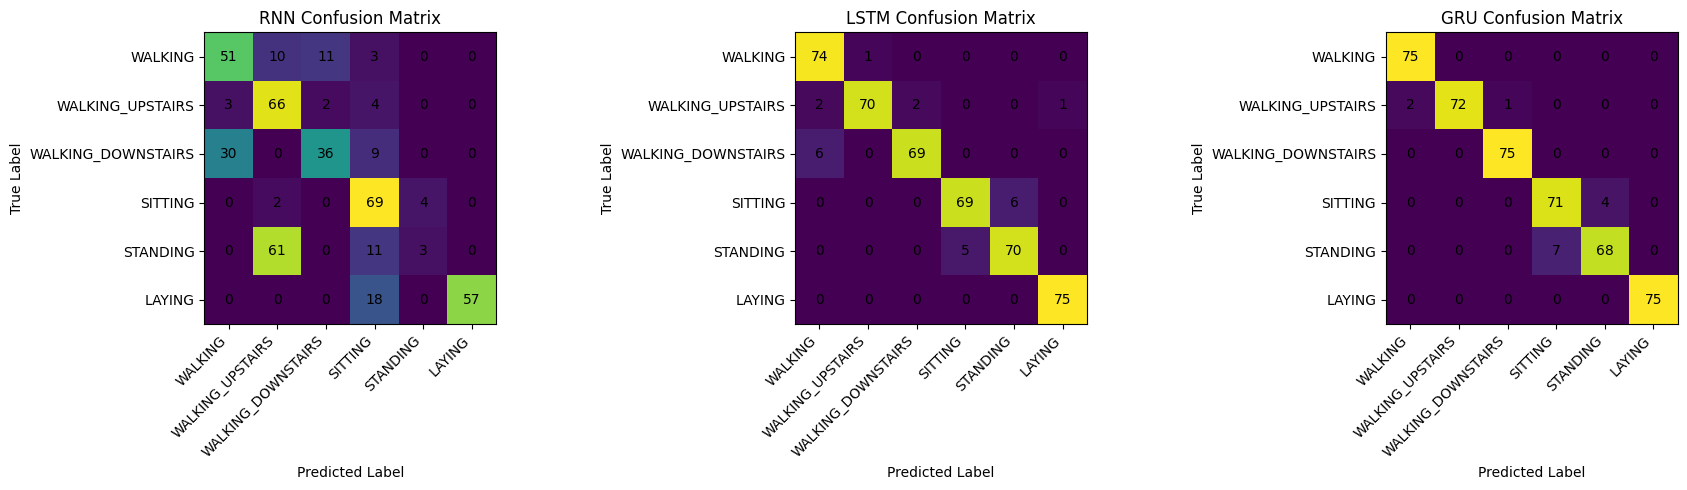

In [19]:
# ============================================================
# 15. CONFUSION MATRICES
# ============================================================

activity_names = [
    "WALKING",
    "WALKING_UPSTAIRS",
    "WALKING_DOWNSTAIRS",
    "SITTING",
    "STANDING",
    "LAYING"
]

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)

results = [
    ("RNN", rnn_results["confusion_matrix"]),
    ("LSTM", lstm_results["confusion_matrix"]),
    ("GRU", gru_results["confusion_matrix"])
]

for ax, (model_name, cm) in zip(axes, results):

    im = ax.imshow(cm)

    ax.set_title(
        f"{model_name} Confusion Matrix"
    )

    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

    ax.set_xticks(range(6))
    ax.set_yticks(range(6))

    ax.set_xticklabels(
        activity_names,
        rotation=45,
        ha="right"
    )

    ax.set_yticklabels(
        activity_names
    )

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):

            ax.text(
                j,
                i,
                cm[i, j],
                ha="center",
                va="center"
            )

plt.tight_layout()
plt.show()

In [20]:
# ============================================================
# 16. ARCHITECTURE COMPARISON TABLE
# ============================================================

architecture_df = pd.DataFrame({

    "Model": [
        "Vanilla RNN",
        "LSTM",
        "GRU"
    ],

    "State Mechanism": [
        "Hidden state",
        "Cell state + hidden state",
        "Hidden state"
    ],

    "Gates": [
        "None",
        "Input + Forget + Output",
        "Update + Reset"
    ],

    "Parameters": [
        rnn_model.count_params(),
        lstm_model.count_params(),
        gru_model.count_params()
    ],

    "Training Time (sec)": [
        rnn_training_time,
        lstm_training_time,
        gru_training_time
    ],

    "Test Macro F1": [
        rnn_results["f1"],
        lstm_results["f1"],
        gru_results["f1"]
    ]
})

display(
    architecture_df.round(4)
)

,Model,State Mechanism,Gates,Parameters,Training Time (sec),Test Macro F1
0,Vanilla RNN,Hidden state,None,1974,27.7629,0.5843
1,LSTM,Cell state + hidden state,Input + Forget + Output,6006,23.6381,0.9489
2,GRU,Hidden state,Update + Reset,4758,20.8359,0.9688


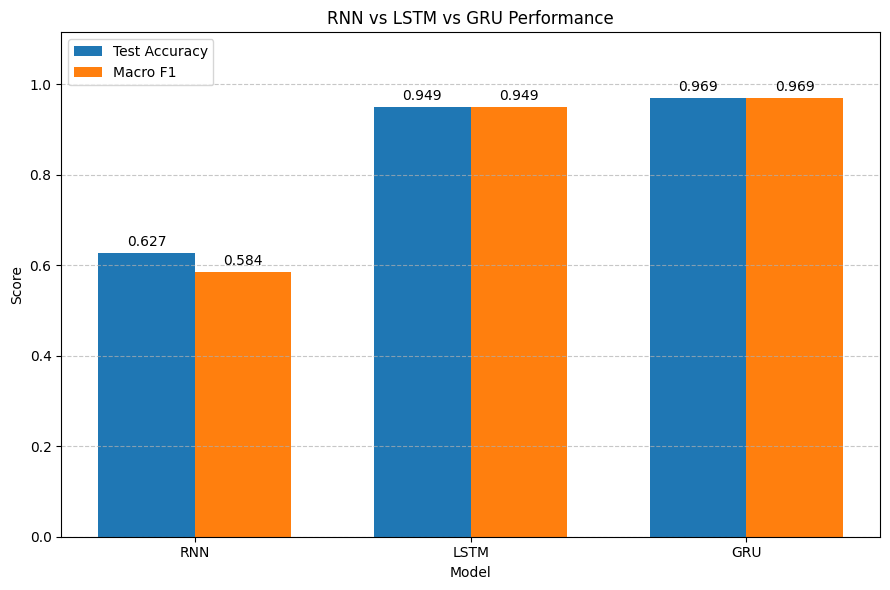

In [21]:
# ============================================================
# 17. PLOT 5 - MODEL PERFORMANCE COMPARISON
# ============================================================
import matplotlib.pyplot as plt
import numpy as np

models = ["RNN", "LSTM", "GRU"]

accuracy_values = [
    rnn_results["accuracy"],
    lstm_results["accuracy"],
    gru_results["accuracy"],
]

f1_values = [rnn_results["f1"], lstm_results["f1"], gru_results["f1"]]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 6))

rects1 = ax.bar(
    x - width / 2, accuracy_values, width, label="Test Accuracy"
)

rects2 = ax.bar(x + width / 2, f1_values, width, label="Macro F1")

# Add data labels on top of the bars
ax.bar_label(rects1, fmt="%.3f", padding=3)
ax.bar_label(rects2, fmt="%.3f", padding=3)

ax.set_xticks(x)
ax.set_xticklabels(models)

ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.set_title("RNN vs LSTM vs GRU Performance")
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.7)

# Add some headroom so labels don't collide with the top border
ax.set_ylim(0, max(max(accuracy_values), max(f1_values)) * 1.15)

plt.tight_layout()
plt.show()

In [22]:
# ============================================================
# 18. SEQUENCE LENGTH EXPERIMENT
# ============================================================

SEQUENCE_LENGTHS = [32, 64, 128]

sequence_results = []

for seq_len in SEQUENCE_LENGTHS:

    print(
        "\n========================================"
    )

    print(
        f"SEQUENCE LENGTH = {seq_len}"
    )

    print(
        "========================================"
    )

    # --------------------------------------------------------
    # Truncate sequences
    # --------------------------------------------------------

    X_train_seq = X_train[:, :seq_len, :]
    X_val_seq = X_val[:, :seq_len, :]
    X_test_seq = X_test[:, :seq_len, :]

    # --------------------------------------------------------
    # Build models
    # --------------------------------------------------------

    rnn_seq_model = build_rnn_model(
        sequence_length=seq_len,
        units=32
    )

    lstm_seq_model = build_lstm_model(
        sequence_length=seq_len,
        units=32
    )

    gru_seq_model = build_gru_model(
        sequence_length=seq_len,
        units=32
    )

    # --------------------------------------------------------
    # Train RNN
    # --------------------------------------------------------

    start = time.time()

    rnn_seq_model.fit(
        X_train_seq,
        y_train,
        validation_data=(X_val_seq, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    rnn_time = time.time() - start

    # --------------------------------------------------------
    # Train LSTM
    # --------------------------------------------------------

    start = time.time()

    lstm_seq_model.fit(
        X_train_seq,
        y_train,
        validation_data=(X_val_seq, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    lstm_time = time.time() - start

    # --------------------------------------------------------
    # Train GRU
    # --------------------------------------------------------

    start = time.time()

    gru_seq_model.fit(
        X_train_seq,
        y_train,
        validation_data=(X_val_seq, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    gru_time = time.time() - start

    # --------------------------------------------------------
    # Evaluate
    # --------------------------------------------------------

    rnn_eval = evaluate_model(
        rnn_seq_model,
        X_test_seq,
        y_test
    )

    lstm_eval = evaluate_model(
        lstm_seq_model,
        X_test_seq,
        y_test
    )

    gru_eval = evaluate_model(
        gru_seq_model,
        X_test_seq,
        y_test
    )

    sequence_results.append({

        "Sequence Length": seq_len,

        "RNN Accuracy":
            rnn_eval["accuracy"],

        "RNN F1":
            rnn_eval["f1"],

        "LSTM Accuracy":
            lstm_eval["accuracy"],

        "LSTM F1":
            lstm_eval["f1"],

        "GRU Accuracy":
            gru_eval["accuracy"],

        "GRU F1":
            gru_eval["f1"],

        "RNN Time":
            rnn_time,

        "LSTM Time":
            lstm_time,

        "GRU Time":
            gru_time
    })


sequence_df = pd.DataFrame(
    sequence_results
)

display(
    sequence_df.round(4)
)


SEQUENCE LENGTH = 32

SEQUENCE LENGTH = 64

SEQUENCE LENGTH = 128


,Sequence Length,RNN Accuracy,RNN F1,LSTM Accuracy,LSTM F1,GRU Accuracy,GRU F1,RNN Time,LSTM Time,GRU Time
0,32,0.8956,0.8959,0.9578,0.9578,0.9467,0.9466,17.5823,16.5728,16.2348
1,64,0.8644,0.8632,0.9578,0.9576,0.9667,0.9667,19.7139,18.0559,17.5636
2,128,0.7822,0.7817,0.9644,0.9645,0.9667,0.9667,26.4955,21.2131,21.0370


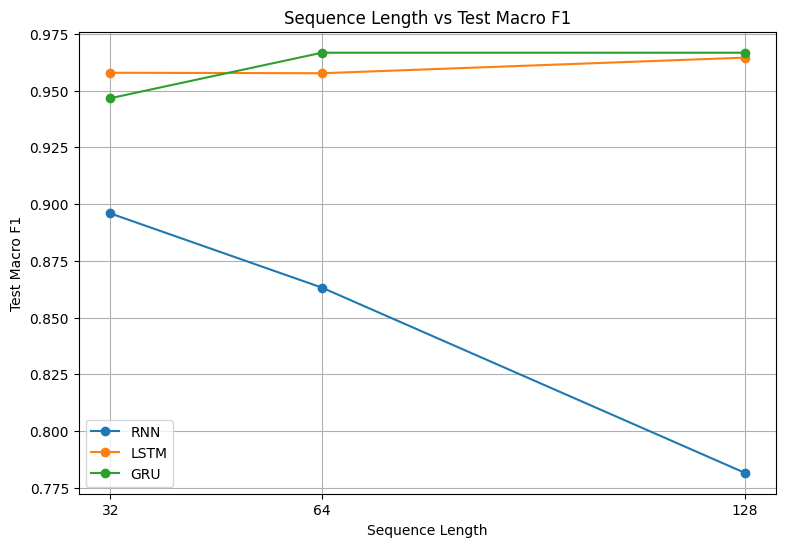

In [23]:
# ============================================================
# 19. PLOT 6 - SEQUENCE LENGTH VS TEST F1
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    sequence_df["Sequence Length"],
    sequence_df["RNN F1"],
    marker="o",
    label="RNN"
)

plt.plot(
    sequence_df["Sequence Length"],
    sequence_df["LSTM F1"],
    marker="o",
    label="LSTM"
)

plt.plot(
    sequence_df["Sequence Length"],
    sequence_df["GRU F1"],
    marker="o",
    label="GRU"
)

plt.xlabel("Sequence Length")
plt.ylabel("Test Macro F1")
plt.title("Sequence Length vs Test Macro F1")

plt.xticks(
    SEQUENCE_LENGTHS
)

plt.legend()
plt.grid(True)

plt.show()

In [24]:
# ============================================================
# 20. SAVE EXPERIMENT RESULTS
# ============================================================

comparison_df.to_csv(
    "/kaggle/working/rnn_lstm_gru_comparison.csv",
    index=False
)

architecture_df.to_csv(
    "/kaggle/working/rnn_lstm_gru_architecture.csv",
    index=False
)

sequence_df.to_csv(
    "/kaggle/working/sequence_length_results.csv",
    index=False
)

print("Results saved successfully.")

Results saved successfully.


In [25]:
# ============================================================
# 21. VIDEO UNDERSTANDING - IMPORTS
# ============================================================

import cv2
import random
import tensorflow as tf

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import (
    preprocess_input
)

print("Video libraries loaded.")

Video libraries loaded.


In [37]:
# ============================================================
# 23. SET UCF101 DATASET PATH
# ============================================================

from pathlib import Path

UCF_ROOT = Path(
    "/kaggle/input/datasets/abdallahwagih/ucf101-videos"
)

UCF_TRAIN_DIR = UCF_ROOT / "train"
UCF_TEST_DIR = UCF_ROOT / "test"

print("==========================================")
print("UCF101 DATASET")
print("==========================================")

print("Root:", UCF_ROOT)
print("Root exists:", UCF_ROOT.exists())

print("\nTrain directory:")
print(UCF_TRAIN_DIR)
print("Exists:", UCF_TRAIN_DIR.exists())

print("\nTest directory:")
print(UCF_TEST_DIR)
print("Exists:", UCF_TEST_DIR.exists())

UCF101 DATASET
Root: /kaggle/input/datasets/abdallahwagih/ucf101-videos
Root exists: True

Train directory:
/kaggle/input/datasets/abdallahwagih/ucf101-videos/train
Exists: True

Test directory:
/kaggle/input/datasets/abdallahwagih/ucf101-videos/test
Exists: True


In [38]:
# ============================================================
# 24. COUNT UCF101 VIDEOS
# ============================================================

VIDEO_EXTENSIONS = {
    ".avi",
    ".mp4",
    ".mov"
}

train_videos = sorted(
    [
        f for f in UCF_TRAIN_DIR.iterdir()
        if f.suffix.lower() in VIDEO_EXTENSIONS
    ]
)

test_videos = sorted(
    [
        f for f in UCF_TEST_DIR.iterdir()
        if f.suffix.lower() in VIDEO_EXTENSIONS
    ]
)

print("==========================================")
print("UCF101 VIDEO COUNT")
print("==========================================")

print("Training videos:", len(train_videos))
print("Testing videos:", len(test_videos))

print("\nSample training videos:")

for video in train_videos[:10]:
    print(video.name)

print("\nSample testing videos:")

for video in test_videos[:10]:
    print(video.name)

UCF101 VIDEO COUNT
Training videos: 594
Testing videos: 224

Sample training videos:
v_CricketShot_g08_c01.avi
v_CricketShot_g08_c02.avi
v_CricketShot_g08_c03.avi
v_CricketShot_g08_c04.avi
v_CricketShot_g08_c05.avi
v_CricketShot_g08_c06.avi
v_CricketShot_g08_c07.avi
v_CricketShot_g09_c01.avi
v_CricketShot_g09_c02.avi
v_CricketShot_g09_c03.avi

Sample testing videos:
v_CricketShot_g01_c01.avi
v_CricketShot_g01_c02.avi
v_CricketShot_g01_c03.avi
v_CricketShot_g01_c04.avi
v_CricketShot_g01_c05.avi
v_CricketShot_g01_c06.avi
v_CricketShot_g01_c07.avi
v_CricketShot_g02_c01.avi
v_CricketShot_g02_c02.avi
v_CricketShot_g02_c03.avi


In [39]:
# ============================================================
# 25. EXTRACT CLASS LABEL FROM VIDEO FILENAME
# ============================================================

def get_class_name(video_path):

    name = video_path.stem

    # Remove "v_"
    name = name[2:]

    # Split:
    # CricketShot_g01_c01
    parts = name.split("_")

    # Everything before _gXX_cXX is the action name
    class_name = "_".join(
        parts[:-2]
    )

    return class_name


# Test
sample_video = UCF_TEST_DIR / "v_CricketShot_g01_c01.avi"

print("Video:")
print(sample_video.name)

print("\nExtracted class:")
print(get_class_name(sample_video))

Video:
v_CricketShot_g01_c01.avi

Extracted class:
CricketShot


In [40]:
# ============================================================
# 26. FIND ALL UCF101 CLASSES
# ============================================================

from collections import Counter

train_classes = [
    get_class_name(video)
    for video in train_videos
]

test_classes = [
    get_class_name(video)
    for video in test_videos
]

train_class_counts = Counter(train_classes)
test_class_counts = Counter(test_classes)

print("==========================================")
print("UCF101 CLASSES")
print("==========================================")

print(
    "Number of training classes:",
    len(train_class_counts)
)

print(
    "Number of testing classes:",
    len(test_class_counts)
)

print("\nFirst 30 training classes:")

for cls in sorted(train_class_counts)[:30]:

    print(
        f"{cls:<30}",
        train_class_counts[cls]
    )

UCF101 CLASSES
Number of training classes: 5
Number of testing classes: 5

First 30 training classes:
CricketShot                    118
PlayingCello                   120
Punch                          121
ShavingBeard                   118
TennisSwing                    117


In [41]:
# ============================================================
# 27. DISPLAY ALL AVAILABLE CLASSES
# ============================================================

available_classes = sorted(
    train_class_counts.keys()
)

print("==========================================")
print("AVAILABLE CLASSES")
print("==========================================")

for i, cls in enumerate(
    available_classes,
    start=1
):

    print(
        f"{i:3}. {cls}"
    )

AVAILABLE CLASSES
  1. CricketShot
  2. PlayingCello
  3. Punch
  4. ShavingBeard
  5. TennisSwing


In [43]:
# ============================================================
# 28. SELECT THE 5 AVAILABLE CLASSES
# ============================================================

SELECTED_CLASSES = [
    "CricketShot",
    "PlayingCello",
    "Punch",
    "ShavingBeard",
    "TennisSwing"
]

print("==========================================")
print("SELECTED VIDEO CLASSES")
print("==========================================")

for i, cls in enumerate(SELECTED_CLASSES, start=1):
    print(f"{i}. {cls}")

SELECTED VIDEO CLASSES
1. CricketShot
2. PlayingCello
3. Punch
4. ShavingBeard
5. TennisSwing


In [44]:
# ============================================================
# 29. VIDEO COUNTS FOR SELECTED CLASSES
# ============================================================

print("==========================================")
print("VIDEO COUNTS")
print("==========================================")

for cls in SELECTED_CLASSES:
    print(
        f"{cls:20s} | "
        f"Train: {train_class_counts[cls]:4d} | "
        f"Test: {test_class_counts[cls]:4d}"
    )

VIDEO COUNTS
CricketShot          | Train:  118 | Test:   49
PlayingCello         | Train:  120 | Test:   44
Punch                | Train:  121 | Test:   39
ShavingBeard         | Train:  118 | Test:   43
TennisSwing          | Train:  117 | Test:   49


In [45]:
# ============================================================
# 30. SELECT VIDEOS FOR THE VIDEO EXPERIMENT
# ============================================================

VIDEOS_PER_CLASS = 20

selected_train_videos = []
selected_test_videos = []

for cls in SELECTED_CLASSES:

    # Get videos belonging to this class
    cls_train = [
        video for video in train_videos
        if get_class_name(video) == cls
    ]

    cls_test = [
        video for video in test_videos
        if get_class_name(video) == cls
    ]

    # Select first 20 videos
    selected_train_videos.extend(
        sorted(cls_train)[:VIDEOS_PER_CLASS]
    )

    selected_test_videos.extend(
        sorted(cls_test)[:VIDEOS_PER_CLASS]
    )

print("==========================================")
print("SELECTED VIDEO DATASET")
print("==========================================")

print(f"Training videos : {len(selected_train_videos)}")
print(f"Testing videos  : {len(selected_test_videos)}")

print("\nTraining videos per class:")
for cls in SELECTED_CLASSES:
    count = sum(
        get_class_name(v) == cls
        for v in selected_train_videos
    )
    print(f"{cls:20s}: {count}")

print("\nTesting videos per class:")
for cls in SELECTED_CLASSES:
    count = sum(
        get_class_name(v) == cls
        for v in selected_test_videos
    )
    print(f"{cls:20s}: {count}")

SELECTED VIDEO DATASET
Training videos : 100
Testing videos  : 100

Training videos per class:
CricketShot         : 20
PlayingCello        : 20
Punch               : 20
ShavingBeard        : 20
TennisSwing         : 20

Testing videos per class:
CricketShot         : 20
PlayingCello        : 20
Punch               : 20
ShavingBeard        : 20
TennisSwing         : 20


In [46]:
# ============================================================
# 31. CREATE CLASS-TO-INDEX MAPPING
# ============================================================

class_to_index = {
    cls: idx
    for idx, cls in enumerate(SELECTED_CLASSES)
}

index_to_class = {
    idx: cls
    for cls, idx in class_to_index.items()
}

print("==========================================")
print("CLASS MAPPING")
print("==========================================")

for cls, idx in class_to_index.items():
    print(f"{cls:20s} -> {idx}")

CLASS MAPPING
CricketShot          -> 0
PlayingCello         -> 1
Punch                -> 2
ShavingBeard         -> 3
TennisSwing          -> 4


In [47]:
# ============================================================
# 32. TRAIN / VALIDATION SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

train_video_paths, val_video_paths = train_test_split(
    selected_train_videos,
    test_size=0.20,
    random_state=42,
    stratify=[
        class_to_index[get_class_name(v)]
        for v in selected_train_videos
    ]
)

print("==========================================")
print("VIDEO SPLIT")
print("==========================================")
print(f"Training   : {len(train_video_paths)}")
print(f"Validation : {len(val_video_paths)}")
print(f"Testing    : {len(selected_test_videos)}")

VIDEO SPLIT
Training   : 80
Validation : 20
Testing    : 100


In [48]:
# ============================================================
# 33. VERIFY CLASS DISTRIBUTION
# ============================================================

from collections import Counter

train_labels = [
    class_to_index[get_class_name(v)]
    for v in train_video_paths
]

val_labels = [
    class_to_index[get_class_name(v)]
    for v in val_video_paths
]

test_labels = [
    class_to_index[get_class_name(v)]
    for v in selected_test_videos
]

print("==========================================")
print("CLASS DISTRIBUTION")
print("==========================================")

print("\nTrain:")
for idx, count in sorted(Counter(train_labels).items()):
    print(f"{index_to_class[idx]:20s}: {count}")

print("\nValidation:")
for idx, count in sorted(Counter(val_labels).items()):
    print(f"{index_to_class[idx]:20s}: {count}")

print("\nTest:")
for idx, count in sorted(Counter(test_labels).items()):
    print(f"{index_to_class[idx]:20s}: {count}")

CLASS DISTRIBUTION

Train:
CricketShot         : 16
PlayingCello        : 16
Punch               : 16
ShavingBeard        : 16
TennisSwing         : 16

Validation:
CricketShot         : 4
PlayingCello        : 4
Punch               : 4
ShavingBeard        : 4
TennisSwing         : 4

Test:
CricketShot         : 20
PlayingCello        : 20
Punch               : 20
ShavingBeard        : 20
TennisSwing         : 20


In [49]:
# ============================================================
# 34. IMPORT LIBRARIES FOR VIDEO PROCESSING
# ============================================================

import os
import cv2
import time
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from collections import Counter

import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

print("TensorFlow version:", tf.__version__)
print("OpenCV version:", cv2.__version__)

TensorFlow version: 2.20.0
OpenCV version: 5.0.0


In [50]:
# ============================================================
# 35. VIDEO EXPERIMENT PARAMETERS
# ============================================================

NUM_FRAMES = 10
FRAME_HEIGHT = 224
FRAME_WIDTH = 224
FRAME_CHANNELS = 3

print("Number of frames per video :", NUM_FRAMES)
print("Frame size                 :", 
      f"{FRAME_HEIGHT} × {FRAME_WIDTH} × {FRAME_CHANNELS}")

Number of frames per video : 10
Frame size                 : 224 × 224 × 3


In [51]:
# ============================================================
# 36. UNIFORM FRAME SAMPLING
# ============================================================

def extract_uniform_frames(video_path, num_frames=10):
    """
    Extract uniformly spaced frames from a video.

    Returns:
        frames: numpy array of shape
                (num_frames, 224, 224, 3)
    """

    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        raise ValueError(f"Could not open video: {video_path}")

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if total_frames <= 0:
        cap.release()
        raise ValueError(f"No frames found in video: {video_path}")

    # Uniformly spaced frame indices
    frame_indices = np.linspace(
        0,
        total_frames - 1,
        num_frames
    ).astype(int)

    frames = []

    for frame_idx in frame_indices:

        cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_idx))

        success, frame = cap.read()

        if not success:
            # If reading fails, use the previous frame
            if len(frames) > 0:
                frame = frames[-1]
            else:
                cap.release()
                raise ValueError(
                    f"Could not read frame from {video_path}"
                )

        # OpenCV gives BGR → convert to RGB
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        # Resize to MobileNetV2 input size
        frame = cv2.resize(
            frame,
            (FRAME_WIDTH, FRAME_HEIGHT)
        )

        frames.append(frame)

    cap.release()

    frames = np.array(frames, dtype=np.uint8)

    return frames

In [53]:
# ============================================================
# 37. TEST FRAME EXTRACTION
# ============================================================

sample_video = selected_train_videos[0]

sample_frames = extract_uniform_frames(
    sample_video,
    NUM_FRAMES
)

print("Video:", sample_video.name)
print("Extracted frames shape:", sample_frames.shape)
print("Expected shape:",
      (NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH, FRAME_CHANNELS))

Video: v_CricketShot_g08_c01.avi
Extracted frames shape: (10, 224, 224, 3)
Expected shape: (10, 224, 224, 3)


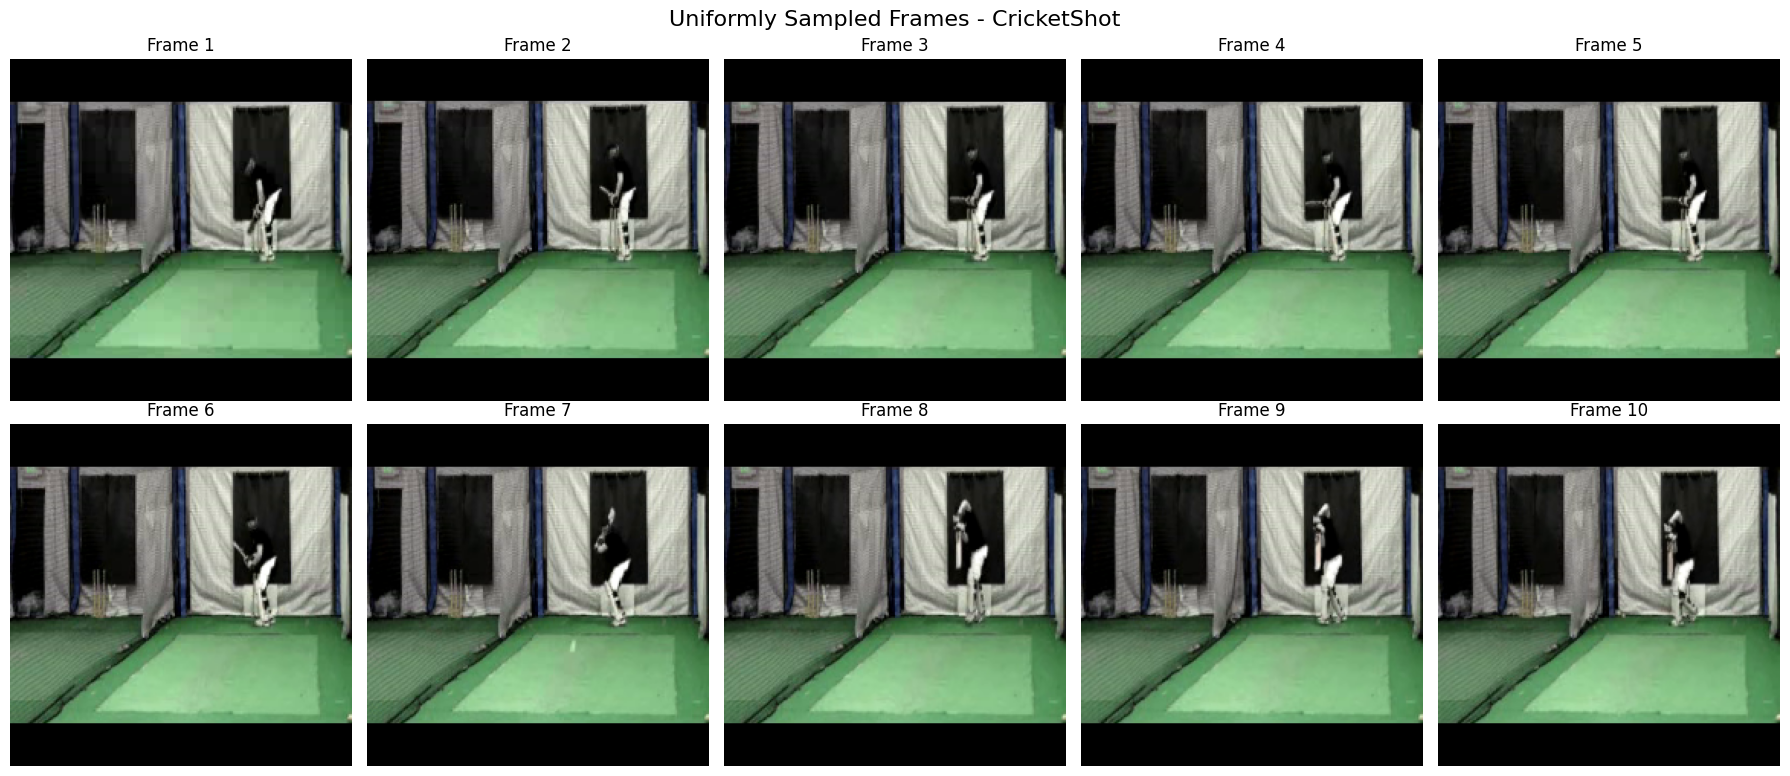

In [54]:
# ============================================================
# 38. PLOT 7 — SAMPLE FRAMES
# ============================================================

plt.figure(figsize=(18, 8))

for i in range(NUM_FRAMES):

    plt.subplot(2, 5, i + 1)

    plt.imshow(sample_frames[i])
    plt.title(f"Frame {i + 1}")
    plt.axis("off")

plt.suptitle(
    f"Uniformly Sampled Frames - {get_class_name(sample_video)}",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [55]:
# ============================================================
# 39. LOAD FROZEN MOBILENETV2
# ============================================================

cnn_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    pooling="avg",
    input_shape=(224, 224, 3)
)

cnn_model.trainable = False

print("MobileNetV2 loaded.")
print("CNN trainable:", cnn_model.trainable)

print(
    "CNN output shape:",
    cnn_model.output_shape
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 loaded.
CNN trainable: False
CNN output shape: (None, 1280)


In [56]:
# ============================================================
# 40. CNN FEATURE EXTRACTION FUNCTION
# ============================================================

def extract_video_features(video_path, cnn_model):

    # Extract 10 frames
    frames = extract_uniform_frames(
        video_path,
        NUM_FRAMES
    )

    # Convert uint8 [0,255] → MobileNetV2 preprocessing
    frames_float = frames.astype(np.float32)

    frames_preprocessed = preprocess_input(
        frames_float
    )

    # CNN processes all 10 frames
    features = cnn_model.predict(
        frames_preprocessed,
        verbose=0
    )

    # Expected shape = (10, 1280)
    return features.astype(np.float32)

In [57]:
# ============================================================
# 41. TEST CNN FEATURE EXTRACTION
# ============================================================

sample_features = extract_video_features(
    sample_video,
    cnn_model
)

print("Video:", sample_video.name)
print("Feature sequence shape:", sample_features.shape)

2026-09-20 06:18:50.642805: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-20 06:18:50.779211: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


Video: v_CricketShot_g08_c01.avi
Feature sequence shape: (10, 1280)


In [58]:
# ============================================================
# 42. EXTRACT CNN FEATURES FOR ALL VIDEOS
# ============================================================

def build_video_feature_dataset(video_paths, cnn_model):

    features_list = []
    labels_list = []

    total = len(video_paths)

    start_time = time.time()

    for i, video_path in enumerate(video_paths):

        features = extract_video_features(
            video_path,
            cnn_model
        )

        label = class_to_index[
            get_class_name(video_path)
        ]

        features_list.append(features)
        labels_list.append(label)

        if (i + 1) % 10 == 0 or (i + 1) == total:
            print(
                f"Processed {i + 1}/{total} videos"
            )

    features_array = np.array(
        features_list,
        dtype=np.float32
    )

    labels_array = np.array(
        labels_list,
        dtype=np.int32
    )

    elapsed = time.time() - start_time

    print("\nFeature extraction completed.")
    print(f"Time taken: {elapsed:.2f} seconds")

    return features_array, labels_array

In [59]:
# ============================================================
# 43. EXTRACT TRAIN FEATURES
# ============================================================

X_video_train, y_video_train = build_video_feature_dataset(
    train_video_paths,
    cnn_model
)

print("\nTrain feature shape:", X_video_train.shape)
print("Train label shape:", y_video_train.shape)

Processed 10/80 videos
Processed 20/80 videos
Processed 30/80 videos
Processed 40/80 videos
Processed 50/80 videos
Processed 60/80 videos
Processed 70/80 videos
Processed 80/80 videos

Feature extraction completed.
Time taken: 14.17 seconds

Train feature shape: (80, 10, 1280)
Train label shape: (80,)


In [60]:
# ============================================================
# 44. EXTRACT VALIDATION FEATURES
# ============================================================

X_video_val, y_video_val = build_video_feature_dataset(
    val_video_paths,
    cnn_model
)

print("\nValidation feature shape:", X_video_val.shape)
print("Validation label shape:", y_video_val.shape)

Processed 10/20 videos
Processed 20/20 videos

Feature extraction completed.
Time taken: 3.79 seconds

Validation feature shape: (20, 10, 1280)
Validation label shape: (20,)


In [61]:
# ============================================================
# 45. EXTRACT TEST FEATURES
# ============================================================

X_video_test, y_video_test = build_video_feature_dataset(
    selected_test_videos,
    cnn_model
)

print("\nTest feature shape:", X_video_test.shape)
print("Test label shape:", y_video_test.shape)

Processed 10/100 videos
Processed 20/100 videos
Processed 30/100 videos
Processed 40/100 videos
Processed 50/100 videos
Processed 60/100 videos
Processed 70/100 videos
Processed 80/100 videos
Processed 90/100 videos
Processed 100/100 videos

Feature extraction completed.
Time taken: 16.86 seconds

Test feature shape: (100, 10, 1280)
Test label shape: (100,)


In [62]:
# ============================================================
# 46. SAVE VIDEO FEATURES
# ============================================================

VIDEO_FEATURE_DIR = Path("/kaggle/working/video_features")
VIDEO_FEATURE_DIR.mkdir(exist_ok=True)

np.save(
    VIDEO_FEATURE_DIR / "X_train.npy",
    X_video_train
)

np.save(
    VIDEO_FEATURE_DIR / "y_train.npy",
    y_video_train
)

np.save(
    VIDEO_FEATURE_DIR / "X_val.npy",
    X_video_val
)

np.save(
    VIDEO_FEATURE_DIR / "y_val.npy",
    y_video_val
)

np.save(
    VIDEO_FEATURE_DIR / "X_test.npy",
    X_video_test
)

np.save(
    VIDEO_FEATURE_DIR / "y_test.npy",
    y_video_test
)

print("Video CNN features saved.")

Video CNN features saved.


In [63]:
# ============================================================
# 47. CNN + LSTM MODEL
# ============================================================

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam

NUM_VIDEO_CLASSES = len(SELECTED_CLASSES)

video_lstm = Sequential([
    LSTM(
        32,
        input_shape=(NUM_FRAMES, 1280)
    ),

    Dropout(0.2),

    Dense(
        16,
        activation="relu"
    ),

    Dense(
        NUM_VIDEO_CLASSES,
        activation="softmax"
    )
])

video_lstm.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

video_lstm.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                   │ (None, 32)             │       168,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 5)              │            85 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 168,677 (658.89 KB)

 Trainable params: 168,677 (658.89 KB)

 Non-trainable params: 0 (0.00 B)

In [64]:
# ============================================================
# 48. TRAIN CNN + LSTM
# ============================================================

VIDEO_EPOCHS = 20
VIDEO_BATCH_SIZE = 8

video_lstm_start = time.time()

history_video_lstm = video_lstm.fit(
    X_video_train,
    y_video_train,

    validation_data=(
        X_video_val,
        y_video_val
    ),

    epochs=VIDEO_EPOCHS,
    batch_size=VIDEO_BATCH_SIZE,
    verbose=1
)

video_lstm_time = time.time() - video_lstm_start

print(
    f"\nCNN-LSTM training time: "
    f"{video_lstm_time:.2f} seconds"
)

Epoch 1/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 0.4750 - loss: 1.4276 - val_accuracy: 0.7500 - val_loss: 1.0392
Epoch 2/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8000 - loss: 0.9091 - val_accuracy: 1.0000 - val_loss: 0.6623
Epoch 3/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9500 - loss: 0.5581 - val_accuracy: 1.0000 - val_loss: 0.4235
Epoch 4/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9875 - loss: 0.4174 - val_accuracy: 1.0000 - val_loss: 0.3025
Epoch 5/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 1.0000 - loss: 0.2792 - val_accuracy: 1.0000 - val_loss: 0.2253
Epoch 6/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 1.0000 - loss: 0.2432 - val_accuracy: 1.0000 - val_loss: 0.1731
Epoch 7/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 1.0000 - loss: 0.1852 - val_accuracy: 1.0000 - val_loss: 0.1345
Epoch 8/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 1.0000 - loss: 0.1547 - val_accuracy: 1.0000 - v

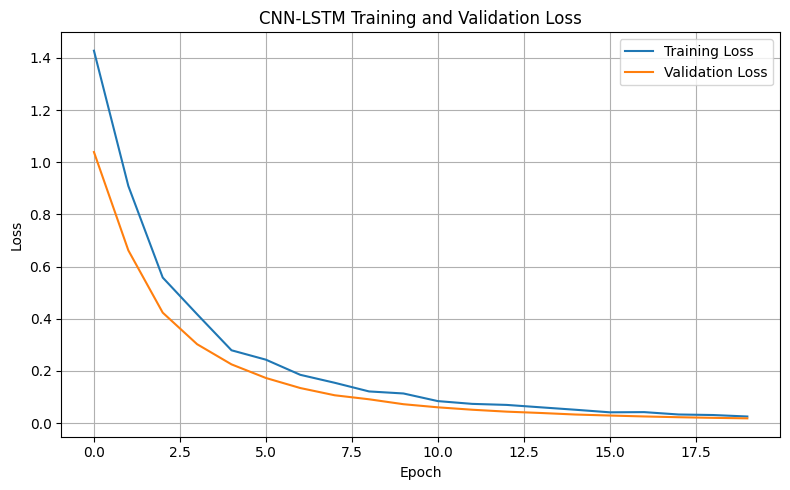

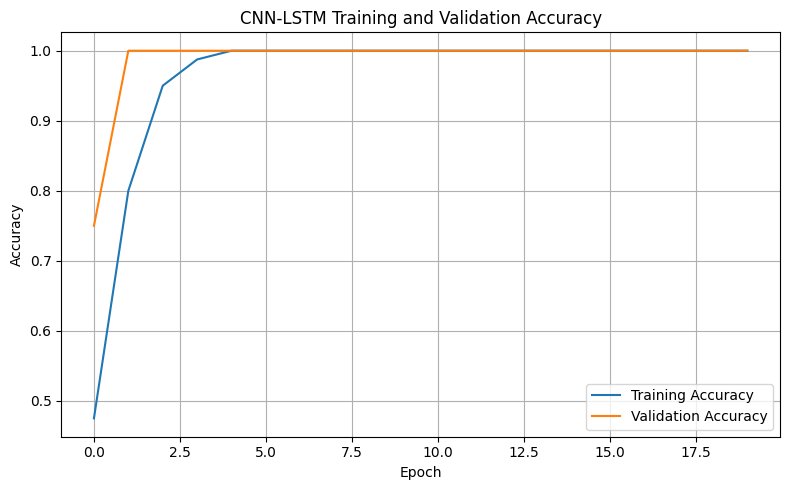

In [65]:
# ============================================================
# 49. PLOT 8 — VIDEO TRAINING CURVES
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history_video_lstm.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_video_lstm.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN-LSTM Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 5))

plt.plot(
    history_video_lstm.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_video_lstm.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN-LSTM Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [66]:
# ============================================================
# 50. EVALUATE CNN + LSTM
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

video_lstm_prob = video_lstm.predict(
    X_video_test,
    verbose=0
)

video_lstm_pred = np.argmax(
    video_lstm_prob,
    axis=1
)

video_lstm_accuracy = accuracy_score(
    y_video_test,
    video_lstm_pred
)

video_lstm_precision = precision_score(
    y_video_test,
    video_lstm_pred,
    average="macro",
    zero_division=0
)

video_lstm_recall = recall_score(
    y_video_test,
    video_lstm_pred,
    average="macro",
    zero_division=0
)

video_lstm_f1 = f1_score(
    y_video_test,
    video_lstm_pred,
    average="macro",
    zero_division=0
)

print("==========================================")
print("CNN-LSTM TEST RESULTS")
print("==========================================")

print(f"Accuracy       : {video_lstm_accuracy:.4f}")
print(f"Macro Precision: {video_lstm_precision:.4f}")
print(f"Macro Recall   : {video_lstm_recall:.4f}")
print(f"Macro F1       : {video_lstm_f1:.4f}")

CNN-LSTM TEST RESULTS
Accuracy       : 0.8400
Macro Precision: 0.8837
Macro Recall   : 0.8400
Macro F1       : 0.8424


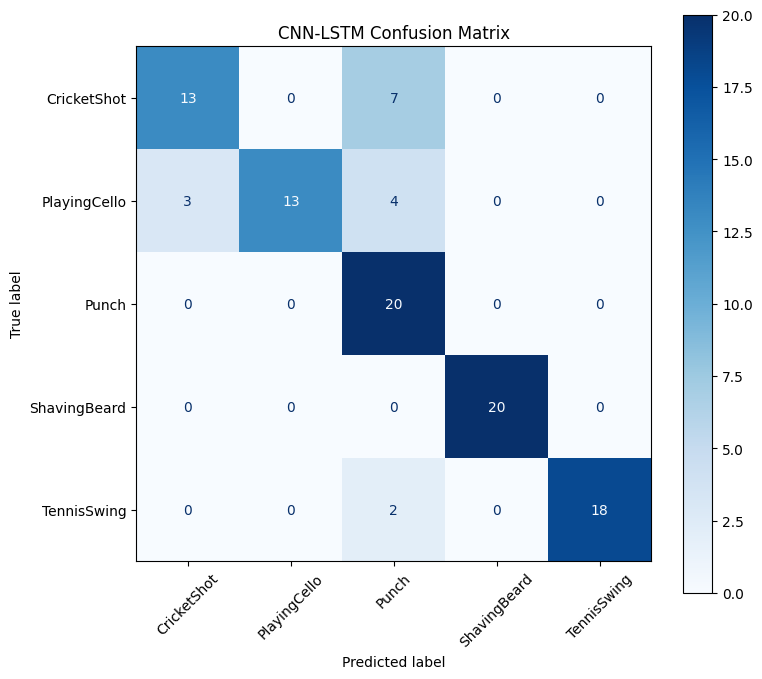

In [67]:
# ============================================================
# 51. PLOT 9 — CNN-LSTM CONFUSION MATRIX
# ============================================================

from sklearn.metrics import ConfusionMatrixDisplay

cm_video_lstm = confusion_matrix(
    y_video_test,
    video_lstm_pred
)

plt.figure(figsize=(8, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_video_lstm,
    display_labels=SELECTED_CLASSES
)

disp.plot(
    values_format="d",
    cmap="Blues",
    ax=plt.gca(),
    xticks_rotation=45
)

plt.title("CNN-LSTM Confusion Matrix")
plt.tight_layout()
plt.show()

In [68]:
# ============================================================
# 52. VIDEO CLASSIFICATION REPORT
# ============================================================

print(
    classification_report(
        y_video_test,
        video_lstm_pred,
        target_names=SELECTED_CLASSES,
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

 CricketShot     0.8125    0.6500    0.7222        20
PlayingCello     1.0000    0.6500    0.7879        20
       Punch     0.6061    1.0000    0.7547        20
ShavingBeard     1.0000    1.0000    1.0000        20
 TennisSwing     1.0000    0.9000    0.9474        20

    accuracy                         0.8400       100
   macro avg     0.8837    0.8400    0.8424       100
weighted avg     0.8837    0.8400    0.8424       100



In [69]:
# ============================================================
# 53. ACTUAL VIDEO PREDICTION WITH CONFIDENCE
# ============================================================

sample_test_index = 0

sample_video_path = selected_test_videos[
    sample_test_index
]

sample_true_label = y_video_test[
    sample_test_index
]

sample_probabilities = video_lstm_prob[
    sample_test_index
]

predicted_index = np.argmax(
    sample_probabilities
)

predicted_class = index_to_class[
    predicted_index
]

actual_class = index_to_class[
    sample_true_label
]

confidence = sample_probabilities[
    predicted_index
]

print("==========================================")
print("VIDEO PREDICTION")
print("==========================================")

print("Video          :", sample_video_path.name)
print("Actual class   :", actual_class)
print("Predicted class:", predicted_class)
print(f"Confidence     : {confidence:.4f}")

VIDEO PREDICTION
Video          : v_CricketShot_g01_c01.avi
Actual class   : CricketShot
Predicted class: Punch
Confidence     : 0.7206


In [70]:
# ============================================================
# 54. CLASS PROBABILITIES
# ============================================================

print("\nClass probabilities:")

for i, cls in enumerate(SELECTED_CLASSES):
    print(
        f"{cls:20s}: "
        f"{sample_probabilities[i]:.4f}"
    )


Class probabilities:
CricketShot         : 0.0781
PlayingCello        : 0.0057
Punch               : 0.7206
ShavingBeard        : 0.0025
TennisSwing         : 0.1932


In [71]:
# ============================================================
# 55. CNN + GRU MODEL
# ============================================================

from tensorflow.keras.layers import GRU

video_gru = Sequential([
    GRU(
        32,
        input_shape=(NUM_FRAMES, 1280)
    ),

    Dropout(0.2),

    Dense(
        16,
        activation="relu"
    ),

    Dense(
        NUM_VIDEO_CLASSES,
        activation="softmax"
    )
])

video_gru.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

video_gru.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_4 (GRU)                     │ (None, 32)             │       126,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 5)              │            85 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 126,757 (495.14 KB)

 Trainable params: 126,757 (495.14 KB)

 Non-trainable params: 0 (0.00 B)

In [72]:
# ============================================================
# 56. TRAIN CNN + GRU
# ============================================================

video_gru_start = time.time()

history_video_gru = video_gru.fit(
    X_video_train,
    y_video_train,

    validation_data=(
        X_video_val,
        y_video_val
    ),

    epochs=VIDEO_EPOCHS,
    batch_size=VIDEO_BATCH_SIZE,
    verbose=1
)

video_gru_time = time.time() - video_gru_start

print(
    f"\nCNN-GRU training time: "
    f"{video_gru_time:.2f} seconds"
)

Epoch 1/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.6125 - loss: 1.0808 - val_accuracy: 0.8000 - val_loss: 0.7655
Epoch 2/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7750 - loss: 0.6549 - val_accuracy: 0.8000 - val_loss: 0.5197
Epoch 3/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8000 - loss: 0.4944 - val_accuracy: 0.9000 - val_loss: 0.4318
Epoch 4/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8125 - loss: 0.4157 - val_accuracy: 0.9500 - val_loss: 0.3702
Epoch 5/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8750 - loss: 0.3651 - val_accuracy: 0.9000 - val_loss: 0.3232
Epoch 6/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9000 - loss: 0.3188 - val_accuracy: 1.0000 - val_loss: 0.2867
Epoch 7/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9500 - loss: 0.2843 - val_accuracy: 1.0000 - val_loss: 0.2595
Epoch 8/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9750 - loss: 0.2551 - val_accuracy: 1.0000 - v

In [73]:
# ============================================================
# 57. EVALUATE CNN + GRU
# ============================================================

video_gru_prob = video_gru.predict(
    X_video_test,
    verbose=0
)

video_gru_pred = np.argmax(
    video_gru_prob,
    axis=1
)

video_gru_accuracy = accuracy_score(
    y_video_test,
    video_gru_pred
)

video_gru_precision = precision_score(
    y_video_test,
    video_gru_pred,
    average="macro",
    zero_division=0
)

video_gru_recall = recall_score(
    y_video_test,
    video_gru_pred,
    average="macro",
    zero_division=0
)

video_gru_f1 = f1_score(
    y_video_test,
    video_gru_pred,
    average="macro",
    zero_division=0
)

print("==========================================")
print("CNN-GRU TEST RESULTS")
print("==========================================")

print(f"Accuracy       : {video_gru_accuracy:.4f}")
print(f"Macro Precision: {video_gru_precision:.4f}")
print(f"Macro Recall   : {video_gru_recall:.4f}")
print(f"Macro F1       : {video_gru_f1:.4f}")

CNN-GRU TEST RESULTS
Accuracy       : 0.7900
Macro Precision: 0.8467
Macro Recall   : 0.7900
Macro F1       : 0.7777


In [74]:
# ============================================================
# 58. VIDEO LSTM vs GRU COMPARISON
# ============================================================

video_comparison = {
    "Model": [
        "CNN-LSTM",
        "CNN-GRU"
    ],

    "Accuracy (%)": [
        video_lstm_accuracy * 100,
        video_gru_accuracy * 100
    ],

    "Macro Precision (%)": [
        video_lstm_precision * 100,
        video_gru_precision * 100
    ],

    "Macro Recall (%)": [
        video_lstm_recall * 100,
        video_gru_recall * 100
    ],

    "Macro F1 (%)": [
        video_lstm_f1 * 100,
        video_gru_f1 * 100
    ],

    "Training Time (s)": [
        video_lstm_time,
        video_gru_time
    ]
}

import pandas as pd

video_comparison_df = pd.DataFrame(
    video_comparison
)

video_comparison_df

,Model,Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1 (%),Training Time (s)
0,CNN-LSTM,84.0,88.371212,84.0,84.243728,4.781916
1,CNN-GRU,79.0,84.666667,79.0,77.773389,4.789340


In [75]:
# ============================================================
# 59. GENERATE SYNTHETIC REVERSAL DATASET
# ============================================================

np.random.seed(42)

NUM_SEQ_SAMPLES = 5000
SEQ_LENGTH = 4

VOCAB_SIZE = 10

# Tokens 1-9 are actual symbols
# 0 is reserved for padding / start token

sequence_inputs = np.random.randint(
    1,
    VOCAB_SIZE,
    size=(NUM_SEQ_SAMPLES, SEQ_LENGTH)
)

sequence_outputs = np.flip(
    sequence_inputs,
    axis=1
)

print("Input shape :", sequence_inputs.shape)
print("Output shape:", sequence_outputs.shape)

print("\nExample:")
print("Input :", sequence_inputs[0])
print("Output:", sequence_outputs[0])

Input shape : (5000, 4)
Output shape: (5000, 4)

Example:
Input : [7 4 8 5]
Output: [5 8 4 7]


In [76]:
# ============================================================
# 60. PREPARE ENCODER / DECODER DATA
# ============================================================

START_TOKEN = 0

decoder_inputs = np.zeros_like(
    sequence_outputs
)

decoder_inputs[:, 0] = START_TOKEN

decoder_inputs[:, 1:] = sequence_outputs[:, :-1]

decoder_targets = sequence_outputs.copy()

print("Encoder input :", sequence_inputs[0])
print("Decoder input :", decoder_inputs[0])
print("Target output :", decoder_targets[0])

Encoder input : [7 4 8 5]
Decoder input : [0 5 8 4]
Target output : [5 8 4 7]


In [77]:
# ============================================================
# 61. SPLIT SEQUENCE DATA
# ============================================================

from sklearn.model_selection import train_test_split

(
    X_seq_train,
    X_seq_temp,
    decoder_train,
    decoder_temp,
    y_seq_train,
    y_seq_temp
) = train_test_split(
    sequence_inputs,
    decoder_inputs,
    decoder_targets,
    test_size=0.30,
    random_state=42
)

(
    X_seq_val,
    X_seq_test,
    decoder_val,
    decoder_test,
    y_seq_val,
    y_seq_test
) = train_test_split(
    X_seq_temp,
    decoder_temp,
    y_seq_temp,
    test_size=0.50,
    random_state=42
)

print("Train:", X_seq_train.shape)
print("Val  :", X_seq_val.shape)
print("Test :", X_seq_test.shape)

Train: (3500, 4)
Val  : (750, 4)
Test : (750, 4)


In [79]:
# ============================================================
# 62. SEQ2SEQ ENCODER-DECODER MODEL
# ============================================================

from tensorflow.keras.layers import (
    Input,
    Embedding,
    LSTM,
    Dense
)

from tensorflow.keras.models import Model

EMBEDDING_DIM = 32
LATENT_DIM = 64

# ------------------------------------------------------------
# Encoder
# ------------------------------------------------------------

encoder_inputs = Input(
    shape=(SEQ_LENGTH,),
    name="encoder_input"
)

encoder_embedding = Embedding(
    input_dim=VOCAB_SIZE,
    output_dim=EMBEDDING_DIM
)(encoder_inputs)

encoder_lstm = LSTM(
    LATENT_DIM,
    return_state=True
)

_, encoder_h, encoder_c = encoder_lstm(
    encoder_embedding
)

encoder_states = [
    encoder_h,
    encoder_c
]

# ------------------------------------------------------------
# Decoder
# ------------------------------------------------------------

decoder_inputs_layer = Input(
    shape=(SEQ_LENGTH,),
    name="decoder_input"
)

decoder_embedding = Embedding(
    input_dim=VOCAB_SIZE,
    output_dim=EMBEDDING_DIM
)(decoder_inputs_layer)

decoder_lstm = LSTM(
    LATENT_DIM,
    return_sequences=True,
    return_state=True
)

decoder_outputs, _, _ = decoder_lstm(
    decoder_embedding,
    initial_state=encoder_states
)

decoder_dense = Dense(
    VOCAB_SIZE,
    activation="softmax"
)

decoder_outputs = decoder_dense(
    decoder_outputs
)

seq2seq_model = Model(
    [encoder_inputs, decoder_inputs_layer],
    decoder_outputs
)

seq2seq_model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

seq2seq_model.summary()

Model: "functional_14"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 4)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_input       │ (None, 4)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 4, 32)     │        320 │ encoder_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 4, 32)     │        320 │ decoder_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_5 (LSTM)       │ [(None, 64),      │     24,832 │ embedding[0][0]   │
│                     │ (None, 64),       │            │                   │
│                     │ (None, 64)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_6 (LSTM)       │ [(None, 4, 64),   │     24,832 │ embedding_1[0][0… │
│                     │ (None, 64),       │            │ lstm_5[0][1],     │
│                     │ (None, 64)]       │            │ lstm_5[0][2]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_28 (Dense)    │ (None, 4, 10)     │        650 │ lstm_6[0][0]      │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 50,954 (199.04 KB)

 Trainable params: 50,954 (199.04 KB)

 Non-trainable params: 0 (0.00 B)

In [80]:
# ============================================================
# 63. TRAIN SEQ2SEQ MODEL
# ============================================================

SEQ_EPOCHS = 20
SEQ_BATCH_SIZE = 64

seq2seq_start = time.time()

history_seq2seq = seq2seq_model.fit(
    [
        X_seq_train,
        decoder_train
    ],

    y_seq_train,

    validation_data=(
        [
            X_seq_val,
            decoder_val
        ],
        y_seq_val
    ),

    epochs=SEQ_EPOCHS,
    batch_size=SEQ_BATCH_SIZE,
    verbose=1
)

seq2seq_time = time.time() - seq2seq_start

print(
    f"\nSeq2Seq training time: "
    f"{seq2seq_time:.2f} seconds"
)

Epoch 1/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.2237 - loss: 2.1258 - val_accuracy: 0.3327 - val_loss: 1.8140
Epoch 2/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4111 - loss: 1.5142 - val_accuracy: 0.5067 - val_loss: 1.1979
Epoch 3/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.6717 - loss: 0.8962 - val_accuracy: 0.8590 - val_loss: 0.5658
Epoch 4/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9352 - loss: 0.3962 - val_accuracy: 0.9723 - val_loss: 0.2595
Epoch 5/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9879 - loss: 0.1950 - val_accuracy: 0.9930 - val_loss: 0.1450
Epoch 6/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9974 - loss: 0.1141 - val_accuracy: 0.9990 - val_loss: 0.0918
Epoch 7/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9994 - loss: 0.0765 - val_accuracy: 0.9990 - val_loss: 0.0664
Epoch 8/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9994 - loss: 0.0565 - val_accuracy: 0.9997 - val_loss

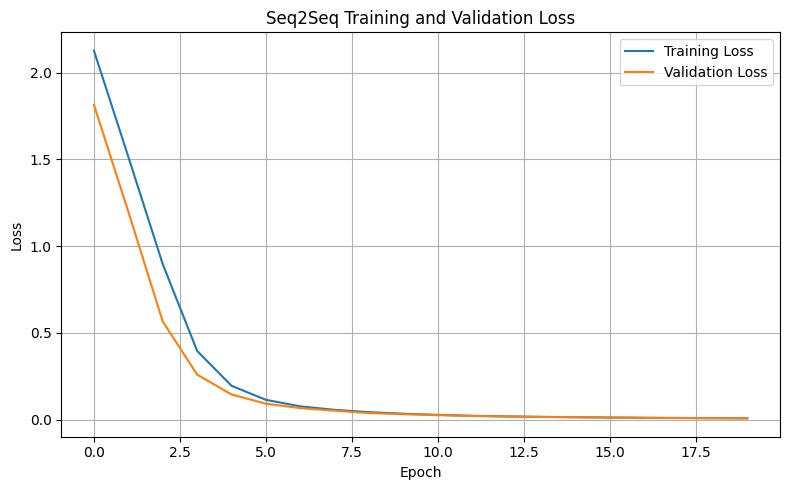

In [81]:
# ============================================================
# 64. SEQ2SEQ TRAINING / VALIDATION LOSS
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history_seq2seq.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_seq2seq.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Seq2Seq Training and Validation Loss"
)

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [82]:
# ============================================================
# 65. TOKEN ACCURACY
# ============================================================

seq_predictions_prob = seq2seq_model.predict(
    [
        X_seq_test,
        decoder_test
    ],
    verbose=0
)

seq_predictions = np.argmax(
    seq_predictions_prob,
    axis=-1
)

token_accuracy = np.mean(
    seq_predictions == y_seq_test
)

print(
    f"Token Accuracy: "
    f"{token_accuracy * 100:.2f}%"
)

Token Accuracy: 100.00%


In [83]:
# ============================================================
# 66. SEQUENCE ACCURACY
# ============================================================

sequence_correct = np.all(
    seq_predictions == y_seq_test,
    axis=1
)

sequence_accuracy = np.mean(
    sequence_correct
)

print(
    f"Sequence Accuracy: "
    f"{sequence_accuracy * 100:.2f}%"
)

Sequence Accuracy: 100.00%


In [84]:
# ============================================================
# 67. FIVE SEQ2SEQ TEST EXAMPLES
# ============================================================

print("==========================================")
print("SEQ2SEQ TEST PREDICTIONS")
print("==========================================")

for i in range(5):

    print(f"\nExample {i + 1}")

    print(
        "Input     :",
        X_seq_test[i]
    )

    print(
        "Expected  :",
        y_seq_test[i]
    )

    print(
        "Predicted  :",
        seq_predictions[i]
    )

    if np.array_equal(
        y_seq_test[i],
        seq_predictions[i]
    ):
        print("Sequence Correct: YES")
    else:
        print("Sequence Correct: NO")

SEQ2SEQ TEST PREDICTIONS

Example 1
Input     : [4 9 8 6]
Expected  : [6 8 9 4]
Predicted  : [6 8 9 4]
Sequence Correct: YES

Example 2
Input     : [4 3 5 9]
Expected  : [9 5 3 4]
Predicted  : [9 5 3 4]
Sequence Correct: YES

Example 3
Input     : [9 3 8 1]
Expected  : [1 8 3 9]
Predicted  : [1 8 3 9]
Sequence Correct: YES

Example 4
Input     : [9 8 6 3]
Expected  : [3 6 8 9]
Predicted  : [3 6 8 9]
Sequence Correct: YES

Example 5
Input     : [3 7 3 9]
Expected  : [9 3 7 3]
Predicted  : [9 3 7 3]
Sequence Correct: YES


In [86]:
# ============================================================
# 68. SEQ2SEQ RESULTS TABLE
# ============================================================

seq2seq_results = pd.DataFrame({
    "Metric": [
        "Token Accuracy (%)",
        "Sequence Accuracy (%)",
        "Training Time (s)"
    ],

    "Value": [
        token_accuracy * 100,
        sequence_accuracy * 100,
        seq2seq_time
    ]
})

seq2seq_results

,Metric,Value
0,Token Accuracy (%),100.000000
1,Sequence Accuracy (%),100.000000
2,Training Time (s),13.295951


In [87]:
# ============================================================
# 69. EFFECT OF RECURRENT UNITS
# ============================================================

def build_rnn_with_units(units):

    model = Sequential([
        tf.keras.layers.SimpleRNN(
            units,
            input_shape=X_train.shape[1:]
        ),

        Dropout(0.2),

        Dense(
            16,
            activation="relu"
        ),

        Dense(
            6,
            activation="softmax"
        )
    ])

    model.compile(
        optimizer=Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


unit_results = []

for units in [16, 32, 64]:

    print(
        f"\n=============================="
        f"\nRNN with {units} units"
        f"\n=============================="
    )

    model = build_rnn_with_units(units)

    start = time.time()

    model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=10,
        batch_size=32,
        verbose=0
    )

    training_time = time.time() - start

    pred = np.argmax(
        model.predict(X_test, verbose=0),
        axis=1
    )

    acc = accuracy_score(
        y_test,
        pred
    )

    f1 = f1_score(
        y_test,
        pred,
        average="macro"
    )

    params = model.count_params()

    unit_results.append([
        units,
        acc * 100,
        f1 * 100,
        params,
        training_time
    ])

unit_results_df = pd.DataFrame(
    unit_results,
    columns=[
        "Units",
        "Accuracy (%)",
        "Macro F1 (%)",
        "Parameters",
        "Training Time (s)"
    ]
)

unit_results_df


RNN with 16 units


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



RNN with 32 units


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



RNN with 64 units


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


,Units,Accuracy (%),Macro F1 (%),Parameters,Training Time (s)
0,16,71.777778,71.294559,790,12.157515
1,32,71.555556,71.624785,1974,11.897712
2,64,69.333333,69.133669,5878,12.919322


In [88]:
# ============================================================
# 70. TWO-RECURRENT-LAYER RNN
# ============================================================

two_layer_rnn = Sequential([
    tf.keras.layers.SimpleRNN(
        32,
        return_sequences=True,
        input_shape=X_train.shape[1:]
    ),

    Dropout(0.2),

    tf.keras.layers.SimpleRNN(
        32
    ),

    Dropout(0.2),

    Dense(
        16,
        activation="relu"
    ),

    Dense(
        6,
        activation="softmax"
    )
])

two_layer_rnn.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

two_layer_rnn.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_7 (SimpleRNN)        │ (None, 128, 32)        │         1,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 128, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_8 (SimpleRNN)        │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_35 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_36 (Dense)                │ (None, 6)              │           102 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,054 (15.84 KB)

 Trainable params: 4,054 (15.84 KB)

 Non-trainable params: 0 (0.00 B)

In [89]:
# ============================================================
# 71. TRAIN TWO-LAYER RNN
# ============================================================

start = time.time()

history_two_layer = two_layer_rnn.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=32,
    verbose=1
)

two_layer_time = time.time() - start

two_layer_pred = np.argmax(
    two_layer_rnn.predict(X_test, verbose=0),
    axis=1
)

print(
    "Two-layer RNN Accuracy:",
    accuracy_score(y_test, two_layer_pred)
)

print(
    "Two-layer RNN Macro F1:",
    f1_score(
        y_test,
        two_layer_pred,
        average="macro"
    )
)

print(
    "Training time:",
    two_layer_time
)

Epoch 1/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 9s 68ms/step - accuracy: 0.4181 - loss: 1.4819 - val_accuracy: 0.5489 - val_loss: 1.1745
Epoch 2/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.5533 - loss: 1.1166 - val_accuracy: 0.6222 - val_loss: 0.9607
Epoch 3/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.6119 - loss: 0.9516 - val_accuracy: 0.6222 - val_loss: 0.8715
Epoch 4/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.6619 - loss: 0.8066 - val_accuracy: 0.7067 - val_loss: 0.6836
Epoch 5/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.7133 - loss: 0.6738 - val_accuracy: 0.7489 - val_loss: 0.5894
Epoch 6/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.7262 - loss: 0.6296 - val_accuracy: 0.7622 - val_loss: 0.5633
Epoch 7/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.7538 - loss: 0.5916 - val_accuracy: 0.8000 - val_loss: 0.5187
Epoch 8/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.7719 - loss: 0.5458 - val_accuracy: 0.8044 - v

In [90]:
# ============================================================
# 72. BIDIRECTIONAL LSTM
# ============================================================

from tensorflow.keras.layers import Bidirectional

bilstm_model = Sequential([
    Bidirectional(
        LSTM(
            32
        ),
        input_shape=X_train.shape[1:]
    ),

    Dropout(0.2),

    Dense(
        16,
        activation="relu"
    ),

    Dense(
        6,
        activation="softmax"
    )
])

bilstm_model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

bilstm_model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 64)             │        10,752 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_37 (Dense)                │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_38 (Dense)                │ (None, 6)              │           102 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,894 (46.46 KB)

 Trainable params: 11,894 (46.46 KB)

 Non-trainable params: 0 (0.00 B)

In [91]:
# ============================================================
# 73. TRAIN BIDIRECTIONAL LSTM
# ============================================================

start = time.time()

history_bilstm = bilstm_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=32,
    verbose=1
)

bilstm_time = time.time() - start

bilstm_pred = np.argmax(
    bilstm_model.predict(
        X_test,
        verbose=0
    ),
    axis=1
)

print(
    "BiLSTM Accuracy:",
    accuracy_score(
        y_test,
        bilstm_pred
    )
)

print(
    "BiLSTM Macro F1:",
    f1_score(
        y_test,
        bilstm_pred,
        average="macro"
    )
)

print(
    "BiLSTM Training Time:",
    bilstm_time
)

Epoch 1/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.4124 - loss: 1.4761 - val_accuracy: 0.6533 - val_loss: 1.1064
Epoch 2/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.7286 - loss: 0.7772 - val_accuracy: 0.8756 - val_loss: 0.4777
Epoch 3/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.8529 - loss: 0.4294 - val_accuracy: 0.9311 - val_loss: 0.2691
Epoch 4/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9186 - loss: 0.2692 - val_accuracy: 0.9400 - val_loss: 0.1980
Epoch 5/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9333 - loss: 0.1947 - val_accuracy: 0.9311 - val_loss: 0.1684
Epoch 6/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9210 - loss: 0.2069 - val_accuracy: 0.9511 - val_loss: 0.1379
Epoch 7/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9395 - loss: 0.1618 - val_accuracy: 0.9556 - val_loss: 0.1402
Epoch 8/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9214 - loss: 0.2205 - val_accuracy: 0.9422 - v

In [92]:
# ============================================================
# 74. SEQUENCE LENGTH EXPERIMENT
# ============================================================

SEQUENCE_LENGTHS = [32, 64, 128]


def build_sequence_model(model_type, sequence_length):

    if model_type == "RNN":
        recurrent_layer = tf.keras.layers.SimpleRNN(
            32,
            input_shape=(sequence_length, 9)
        )

    elif model_type == "LSTM":
        recurrent_layer = LSTM(
            32,
            input_shape=(sequence_length, 9)
        )

    elif model_type == "GRU":
        recurrent_layer = GRU(
            32,
            input_shape=(sequence_length, 9)
        )

    model = Sequential([
        recurrent_layer,

        Dropout(0.2),

        Dense(
            16,
            activation="relu"
        ),

        Dense(
            6,
            activation="softmax"
        )
    ])

    model.compile(
        optimizer=Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [93]:
# ============================================================
# 75. RUN SEQUENCE LENGTH EXPERIMENT
# ============================================================

sequence_length_results = []

for T in SEQUENCE_LENGTHS:

    print(
        f"\n\n=============================="
        f"\nSequence Length = {T}"
        f"\n=============================="
    )

    Xtr = X_train[:, :T, :]
    Xv = X_val[:, :T, :]
    Xte = X_test[:, :T, :]

    for model_type in ["RNN", "LSTM", "GRU"]:

        print(f"\nTraining {model_type}...")

        model = build_sequence_model(
            model_type,
            T
        )

        start = time.time()

        model.fit(
            Xtr,
            y_train,
            validation_data=(Xv, y_val),
            epochs=10,
            batch_size=32,
            verbose=0
        )

        training_time = time.time() - start

        pred = np.argmax(
            model.predict(
                Xte,
                verbose=0
            ),
            axis=1
        )

        f1 = f1_score(
            y_test,
            pred,
            average="macro"
        )

        sequence_length_results.append([
            T,
            model_type,
            f1 * 100,
            training_time
        ])

        print(
            f"{model_type} | "
            f"F1 = {f1 * 100:.2f}% | "
            f"Time = {training_time:.2f}s"
        )

sequence_length_df = pd.DataFrame(
    sequence_length_results,
    columns=[
        "Sequence Length",
        "Model",
        "Macro F1 (%)",
        "Training Time (s)"
    ]
)

sequence_length_df



Sequence Length = 32

Training RNN...


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


RNN | F1 = 78.44% | Time = 8.94s

Training LSTM...


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


LSTM | F1 = 94.24% | Time = 6.37s

Training GRU...


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


... (10 outputs left out)

LSTM | F1 = 86.56% | Time = 7.96s

Training GRU...


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


GRU | F1 = 96.90% | Time = 7.97s


,Sequence Length,Model,Macro F1 (%),Training Time (s)
0,32,RNN,78.436037,8.941237
1,32,LSTM,94.236352,6.370539
2,32,GRU,90.163646,6.273274
3,64,RNN,70.182999,9.643913
4,64,LSTM,96.442919,7.197876
5,64,GRU,90.550275,6.858812
6,128,RNN,71.995346,12.729195
7,128,LSTM,86.559965,7.955514
8,128,GRU,96.895370,7.970510


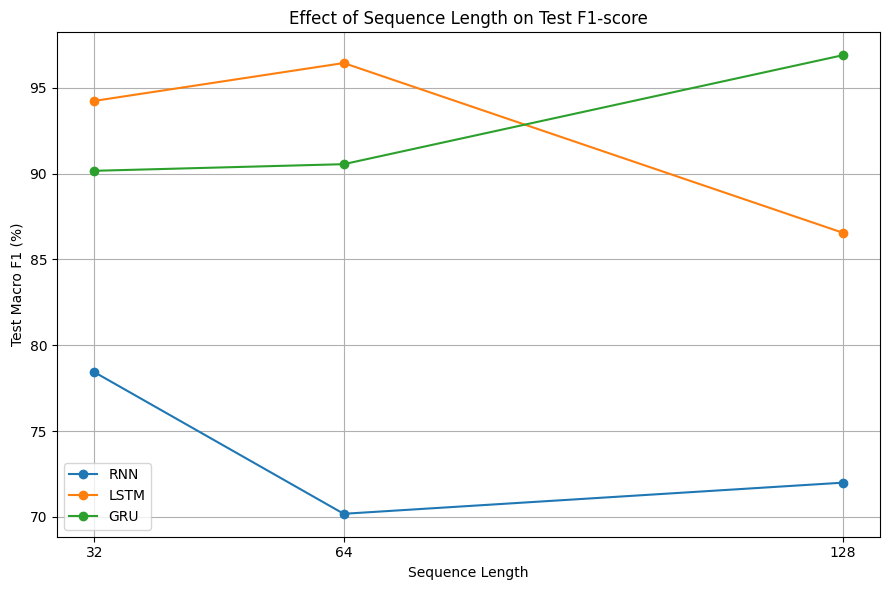

In [94]:
# ============================================================
# 76. PLOT 6 — SEQUENCE LENGTH VS TEST F1
# ============================================================

plt.figure(figsize=(9, 6))

for model_type in ["RNN", "LSTM", "GRU"]:

    subset = sequence_length_df[
        sequence_length_df["Model"] == model_type
    ]

    plt.plot(
        subset["Sequence Length"],
        subset["Macro F1 (%)"],
        marker="o",
        label=model_type
    )

plt.xlabel("Sequence Length")
plt.ylabel("Test Macro F1 (%)")

plt.title(
    "Effect of Sequence Length on Test F1-score"
)

plt.xticks(SEQUENCE_LENGTHS)

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

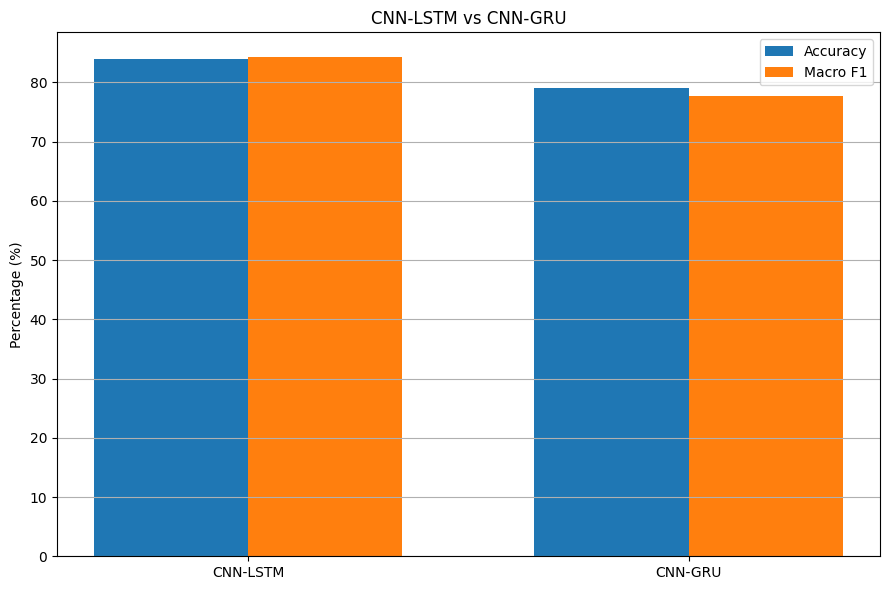

In [95]:
# ============================================================
# 77. VIDEO LSTM vs GRU PERFORMANCE PLOT
# ============================================================

video_plot_df = pd.DataFrame({
    "Model": ["CNN-LSTM", "CNN-GRU"],

    "Accuracy": [
        video_lstm_accuracy * 100,
        video_gru_accuracy * 100
    ],

    "Macro F1": [
        video_lstm_f1 * 100,
        video_gru_f1 * 100
    ]
})

x = np.arange(len(video_plot_df))
width = 0.35

plt.figure(figsize=(9, 6))

plt.bar(
    x - width / 2,
    video_plot_df["Accuracy"],
    width,
    label="Accuracy"
)

plt.bar(
    x + width / 2,
    video_plot_df["Macro F1"],
    width,
    label="Macro F1"
)

plt.xticks(
    x,
    video_plot_df["Model"]
)

plt.ylabel("Percentage (%)")
plt.title("CNN-LSTM vs CNN-GRU")
plt.legend()
plt.grid(axis="y")

plt.tight_layout()
plt.show()

In [96]:
# ============================================================
# 78. CONSOLIDATED VIDEO RESULTS
# ============================================================

video_final_results = pd.DataFrame({
    "Model": [
        "CNN-LSTM",
        "CNN-GRU"
    ],

    "Accuracy (%)": [
        video_lstm_accuracy * 100,
        video_gru_accuracy * 100
    ],

    "Macro Precision (%)": [
        video_lstm_precision * 100,
        video_gru_precision * 100
    ],

    "Macro Recall (%)": [
        video_lstm_recall * 100,
        video_gru_recall * 100
    ],

    "Macro F1 (%)": [
        video_lstm_f1 * 100,
        video_gru_f1 * 100
    ],

    "Parameters": [
        video_lstm.count_params(),
        video_gru.count_params()
    ],

    "Training Time (s)": [
        video_lstm_time,
        video_gru_time
    ]
})

video_final_results

,Model,Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1 (%),Parameters,Training Time (s)
0,CNN-LSTM,84.0,88.371212,84.0,84.243728,168677,4.781916
1,CNN-GRU,79.0,84.666667,79.0,77.773389,126757,4.789340


In [97]:
# ============================================================
# 79. SAVE EXPERIMENT RESULTS
# ============================================================

RESULTS_DIR = Path("/kaggle/working/experiment6_results")
RESULTS_DIR.mkdir(exist_ok=True)

video_final_results.to_csv(
    RESULTS_DIR / "video_results.csv",
    index=False
)

video_comparison_df.to_csv(
    RESULTS_DIR / "video_lstm_gru_comparison.csv",
    index=False
)

seq2seq_results.to_csv(
    RESULTS_DIR / "seq2seq_results.csv",
    index=False
)

unit_results_df.to_csv(
    RESULTS_DIR / "recurrent_units_results.csv",
    index=False
)

sequence_length_df.to_csv(
    RESULTS_DIR / "sequence_length_results.csv",
    index=False
)

print(
    "All experiment result tables saved to:"
)

print(RESULTS_DIR)

All experiment result tables saved to:
/kaggle/working/experiment6_results


In [99]:
# ============================================================
# 80. FINAL EXPERIMENT SUMMARY
# ============================================================

print("=" * 70)
print("CS3807 DEEP LEARNING LAB — EXPERIMENT 6")
print("FINAL SUMMARY")
print("=" * 70)

print("\nVIDEO DATASET")
print("-" * 70)

print("Selected classes:")
for i, cls in enumerate(SELECTED_CLASSES):
    print(f"{i}: {cls}")

print("\nCNN:")
print("Model              : MobileNetV2")
print("Frozen             :", not cnn_model.trainable)
print("Frames/video       :", NUM_FRAMES)
print("Frame size         : 224 × 224 × 3")
print("CNN feature size   : 1280")
print("Feature sequence   : 10 × 1280")

print("\nVIDEO RESULTS")
print("-" * 70)

print(video_final_results.to_string(index=False))

print("\nSEQ2SEQ RESULTS")
print("-" * 70)

print(seq2seq_results.to_string(index=False))

print("\nSEQUENCE LENGTH RESULTS")
print("-" * 70)

print(sequence_length_df.to_string(index=False))



CS3807 DEEP LEARNING LAB — EXPERIMENT 6
FINAL SUMMARY

VIDEO DATASET
----------------------------------------------------------------------
Selected classes:
0: CricketShot
1: PlayingCello
2: Punch
3: ShavingBeard
4: TennisSwing

CNN:
Model              : MobileNetV2
Frozen             : True
Frames/video       : 10
Frame size         : 224 × 224 × 3
CNN feature size   : 1280
Feature sequence   : 10 × 1280

VIDEO RESULTS
----------------------------------------------------------------------
   Model  Accuracy (%)  Macro Precision (%)  Macro Recall (%)  Macro F1 (%)  Parameters  Training Time (s)
CNN-LSTM          84.0            88.371212              84.0     84.243728      168677           4.781916
 CNN-GRU          79.0            84.666667              79.0     77.773389      126757           4.789340

SEQ2SEQ RESULTS
----------------------------------------------------------------------
               Metric      Value
   Token Accuracy (%) 100.000000
Sequence Accuracy (%) 100.000

In [100]:
# ============================================================
# Generate dataset
# ============================================================

NUM_SAMPLES = 5000

INPUT_LENGTH = 5
OUTPUT_LENGTH = 3
VOCAB_SIZE = 10       # tokens 0-9
START_TOKEN = 0

np.random.seed(42)

# Generate input sequences using values 1-9
X_var = np.random.randint(
    1,
    VOCAB_SIZE,
    size=(NUM_SAMPLES, INPUT_LENGTH)
)

# Output = reverse of the last 3 input elements
y_var = np.flip(
    X_var[:, -OUTPUT_LENGTH:],
    axis=1
)

print("Input shape :", X_var.shape)
print("Output shape:", y_var.shape)

print("\nExample:")
print("Input :", X_var[0])
print("Output:", y_var[0])

Input shape : (5000, 5)
Output shape: (5000, 3)

Example:
Input : [7 4 8 5 7]
Output: [7 5 8]


In [101]:
# ============================================================
# Decoder input for teacher forcing
# ============================================================

decoder_input_var = np.zeros_like(y_var)

decoder_input_var[:, 0] = START_TOKEN
decoder_input_var[:, 1:] = y_var[:, :-1]

print("Target sequence :")
print(y_var[0])

print("\nDecoder input:")
print(decoder_input_var[0])

Target sequence :
[7 5 8]

Decoder input:
[0 7 5]


In [102]:
# ============================================================
# Train / Validation / Test split
# ============================================================

X_var_train, X_var_temp, y_var_train, y_var_temp, dec_var_train, dec_var_temp = train_test_split(
    X_var,
    y_var,
    decoder_input_var,
    test_size=0.30,
    random_state=42
)

X_var_val, X_var_test, y_var_val, y_var_test, dec_var_val, dec_var_test = train_test_split(
    X_var_temp,
    y_var_temp,
    dec_var_temp,
    test_size=0.50,
    random_state=42
)

print("Training samples  :", len(X_var_train))
print("Validation samples:", len(X_var_val))
print("Test samples     :", len(X_var_test))

Training samples  : 3500
Validation samples: 750
Test samples     : 750


In [103]:
# ============================================================
# Encoder-Decoder LSTM
# Input length = 5
# Output length = 3
# ============================================================

EMBEDDING_DIM = 32
LATENT_DIM = 64

# -------------------------
# Encoder
# -------------------------
encoder_inputs = Input(
    shape=(INPUT_LENGTH,),
    name="encoder_input"
)

encoder_embedding = Embedding(
    input_dim=VOCAB_SIZE,
    output_dim=EMBEDDING_DIM,
    name="encoder_embedding"
)(encoder_inputs)

encoder_lstm = LSTM(
    LATENT_DIM,
    return_state=True,
    name="encoder_lstm"
)

_, state_h, state_c = encoder_lstm(
    encoder_embedding
)

encoder_states = [state_h, state_c]


# -------------------------
# Decoder
# -------------------------
decoder_inputs = Input(
    shape=(OUTPUT_LENGTH,),
    name="decoder_input"
)

decoder_embedding = Embedding(
    input_dim=VOCAB_SIZE,
    output_dim=EMBEDDING_DIM,
    name="decoder_embedding"
)(decoder_inputs)

decoder_lstm = LSTM(
    LATENT_DIM,
    return_sequences=True,
    return_state=True,
    name="decoder_lstm"
)

decoder_outputs, _, _ = decoder_lstm(
    decoder_embedding,
    initial_state=encoder_states
)

decoder_dense = Dense(
    VOCAB_SIZE,
    activation="softmax",
    name="decoder_output"
)

decoder_outputs = decoder_dense(decoder_outputs)


# -------------------------
# Complete model
# -------------------------
var_seq2seq_model = Model(
    [encoder_inputs, decoder_inputs],
    decoder_outputs
)

var_seq2seq_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

var_seq2seq_model.summary()

Model: "functional_29"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 5)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_input       │ (None, 3)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_embedding   │ (None, 5, 32)     │        320 │ encoder_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_embedding   │ (None, 3, 32)     │        320 │ decoder_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm (LSTM) │ [(None, 64),      │     24,832 │ encoder_embeddin… │
│                     │ (None, 64),       │            │                   │
│                     │ (None, 64)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ [(None, 3, 64),   │     24,832 │ decoder_embeddin… │
│                     │ (None, 64),       │            │ encoder_lstm[0][… │
│                     │ (None, 64)]       │            │ encoder_lstm[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_output      │ (None, 3, 10)     │        650 │ decoder_lstm[0][… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 50,954 (199.04 KB)

 Trainable params: 50,954 (199.04 KB)

 Non-trainable params: 0 (0.00 B)

In [104]:
# ============================================================
# Train variable-length seq2seq model
# ============================================================

start_time = time.time()

history_var = var_seq2seq_model.fit(
    [X_var_train, dec_var_train],
    y_var_train[..., np.newaxis],
    validation_data=(
        [X_var_val, dec_var_val],
        y_var_val[..., np.newaxis]
    ),
    epochs=20,
    batch_size=64,
    verbose=1
)

var_training_time = time.time() - start_time

print(f"\nTraining Time: {var_training_time:.2f} seconds")

Epoch 1/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.3115 - loss: 2.1452 - val_accuracy: 0.3800 - val_loss: 1.7980
Epoch 2/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4280 - loss: 1.5186 - val_accuracy: 0.4800 - val_loss: 1.3014
Epoch 3/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.6148 - loss: 1.0147 - val_accuracy: 0.8124 - val_loss: 0.6883
Epoch 4/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9240 - loss: 0.4408 - val_accuracy: 0.9796 - val_loss: 0.2703
Epoch 5/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9948 - loss: 0.1755 - val_accuracy: 0.9991 - val_loss: 0.1233
Epoch 6/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9999 - loss: 0.0916 - val_accuracy: 0.9991 - val_loss: 0.0736
Epoch 7/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 1.0000 - loss: 0.0579 - val_accuracy: 0.9991 - val_loss: 0.0512
Epoch 8/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 1.0000 - loss: 0.0411 - val_accuracy: 0.9996 - val_loss

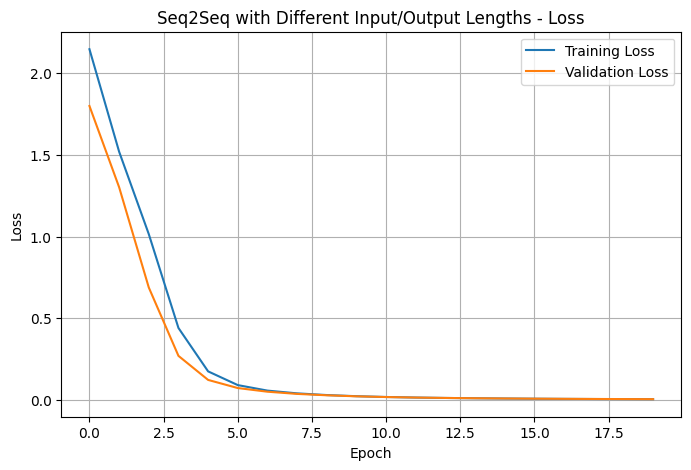

In [105]:
# ============================================================
# Training and Validation Loss
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history_var.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_var.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Seq2Seq with Different Input/Output Lengths - Loss")
plt.legend()
plt.grid(True)
plt.show()

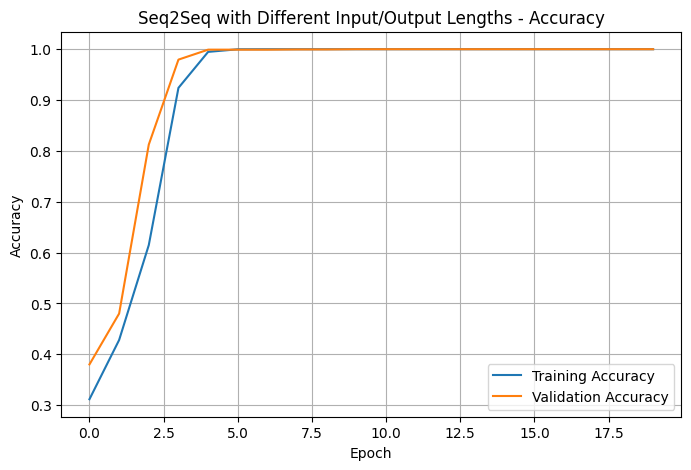

In [106]:
# ============================================================
# Training and Validation Accuracy
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history_var.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_var.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Seq2Seq with Different Input/Output Lengths - Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [107]:
# ============================================================
# Test Evaluation
# ============================================================

test_loss, test_token_accuracy = var_seq2seq_model.evaluate(
    [X_var_test, dec_var_test],
    y_var_test[..., np.newaxis],
    verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Token Accuracy: {test_token_accuracy * 100:.2f}%")

Test Loss: 0.0056
Test Token Accuracy: 100.00%


In [108]:
# ============================================================
# Predictions
# ============================================================

var_predictions = var_seq2seq_model.predict(
    [X_var_test, dec_var_test],
    verbose=0
)

var_pred_tokens = np.argmax(
    var_predictions,
    axis=-1
)

print("Prediction shape:", var_pred_tokens.shape)
print("Expected shape  :", y_var_test.shape)

Prediction shape: (750, 3)
Expected shape  : (750, 3)


In [109]:
# ============================================================
# Token Accuracy
# ============================================================

correct_tokens = np.sum(
    var_pred_tokens == y_var_test
)

total_tokens = y_var_test.size

var_token_accuracy = (
    correct_tokens / total_tokens
)

print(f"Correct tokens: {correct_tokens}")
print(f"Total tokens  : {total_tokens}")
print(f"Token Accuracy: {var_token_accuracy * 100:.2f}%")

Correct tokens: 2250
Total tokens  : 2250
Token Accuracy: 100.00%


In [112]:
# ============================================================
# Sequence Accuracy
# ============================================================

sequence_correct = np.all(
    var_pred_tokens == y_var_test,
    axis=1
)

var_sequence_accuracy = np.mean(
    sequence_correct
)

correct_sequences = np.sum(sequence_correct)
total_sequences = len(y_var_test)

print(f"Correct sequences: {correct_sequences}")
print(f"Total sequences  : {total_sequences}")
print(f"Sequence Accuracy: {var_sequence_accuracy * 100:.2f}%")

Correct sequences: 750
Total sequences  : 750
Sequence Accuracy: 100.00%


In [113]:
# ============================================================
# Display Test Examples
# ============================================================

NUM_EXAMPLES = 5

print("=" * 70)
print("SEQ2SEQ TEST EXAMPLES")
print("=" * 70)

for i in range(NUM_EXAMPLES):

    print(f"\nExample {i + 1}")

    print("Input sequence    :", X_var_test[i])

    print("Expected output   :", y_var_test[i])

    print("Predicted output  :", var_pred_tokens[i])

    if np.array_equal(
        y_var_test[i],
        var_pred_tokens[i]
    ):
        print("Status            : CORRECT")
    else:
        print("Status            : INCORRECT")

SEQ2SEQ TEST EXAMPLES

Example 1
Input sequence    : [6 3 8 2 5]
Expected output   : [5 2 8]
Predicted output  : [5 2 8]
Status            : CORRECT

Example 2
Input sequence    : [1 7 4 3 9]
Expected output   : [9 3 4]
Predicted output  : [9 3 4]
Status            : CORRECT

Example 3
Input sequence    : [4 9 6 2 6]
Expected output   : [6 2 6]
Predicted output  : [6 2 6]
Status            : CORRECT

Example 4
Input sequence    : [4 5 4 6 4]
Expected output   : [4 6 4]
Predicted output  : [4 6 4]
Status            : CORRECT

Example 5
Input sequence    : [6 7 4 3 5]
Expected output   : [5 3 4]
Predicted output  : [5 3 4]
Status            : CORRECT


In [114]:
# ============================================================
# Final Results
# ============================================================

variable_seq2seq_results = {
    "Input Length": INPUT_LENGTH,
    "Output Length": OUTPUT_LENGTH,
    "Training Samples": len(X_var_train),
    "Validation Samples": len(X_var_val),
    "Test Samples": len(X_var_test),
    "Test Loss": test_loss,
    "Token Accuracy (%)": var_token_accuracy * 100,
    "Sequence Accuracy (%)": var_sequence_accuracy * 100,
    "Training Time (s)": var_training_time
}

variable_seq2seq_results

{'Input Length': 5,
 'Output Length': 3,
 'Training Samples': 3500,
 'Validation Samples': 750,
 'Test Samples': 750,
 'Test Loss': 0.005567215383052826,
 'Token Accuracy (%)': np.float64(100.0),
 'Sequence Accuracy (%)': np.float64(100.0),
 'Training Time (s)': 12.335774421691895}

In [115]:
# ============================================================
# Compare Original and Different-Length Seq2Seq
# ============================================================

comparison_data = {
    "Experiment": [
        "Original Seq2Seq",
        "Different-Length Seq2Seq"
    ],

    "Input Length": [
        SEQ_LENGTH,
        INPUT_LENGTH
    ],

    "Output Length": [
        SEQ_LENGTH,
        OUTPUT_LENGTH
    ],

    "Token Accuracy (%)": [
        np.mean(seq_predictions == y_seq_test) * 100,
        var_token_accuracy * 100
    ],

    "Sequence Accuracy (%)": [
        np.mean(
            np.all(
                seq_predictions == y_seq_test,
                axis=1
            )
        ) * 100,

        var_sequence_accuracy * 100
    ]
}

comparison_df = pd.DataFrame(comparison_data)

display(comparison_df)

,Experiment,Input Length,Output Length,Token Accuracy (%),Sequence Accuracy (%)
0,Original Seq2Seq,4,4,100.0,100.0
1,Different-Length Seq2Seq,5,3,100.0,100.0


In [116]:
# ============================================================
# Requirement Verification
# ============================================================

print("=" * 70)
print("ADDITIONAL EXERCISE 7 - REQUIREMENT CHECK")
print("=" * 70)

print(f"Input sequence length  : {INPUT_LENGTH}")
print(f"Output sequence length : {OUTPUT_LENGTH}")

if INPUT_LENGTH != OUTPUT_LENGTH:
    print("\n✓ Requirement satisfied!")
    print("✓ Input and output sequence lengths are different.")
else:
    print("\n✗ Requirement NOT satisfied.")

ADDITIONAL EXERCISE 7 - REQUIREMENT CHECK
Input sequence length  : 5
Output sequence length : 3

✓ Requirement satisfied!
✓ Input and output sequence lengths are different.
